# Results Collation & Comparison
## Apple vs Banana Image Classifier

**Project:** Apple vs Banana image classification
**Inputs:** Four `results_PCn.zip` files exported by `Model_Training_and_Experiments.ipynb` Section 20 (one per computer)
**Goal:** Verify the 16 runs are comparable, analyse the combined evidence, and make an explicit, auditable deployment decision

This notebook does not retrain any model and does not modify Notebook 1's results - it is a read-only analysis of what the four computers already produced. It takes the four ZIPs, the executed Notebook 1 files when a discrepancy needs investigating, and nothing else.

**A completed run is not the same as a valid run.** A notebook can finish without errors while pointed at a different dataset, running with a different configuration, or left in `QUICK_TEST` mode. Section 3 checks for exactly that, before anything downstream is allowed to average across runs.

## **Overview:**
 1. Configuration & Experiment Definition
 2. Results Discovery & Loading
 3. Experiment Integrity & Completeness Audit
 4. Dataset & Test-Set Consistency
 5. Standard Performance Comparison
 6. Confusion Matrices & Learning Behaviour
 7. Model-by-Model Interpretation
 8. Cross-Computer Reproducibility
 9. Error Analysis
 10. Student-versus-Public Generalisation
 11. Confidence & Reliability Analysis
 12. Feature-Space Analysis [STRETCH]
 13. Test-Time Augmentation [STRETCH]
 14. Unsupported-Input / OOD Analysis [STRETCH]
 15. Combined Reliability Strategy [STRETCH]
 16. Computational Comparison 
 17. Statistical & Practical Comparison
 18. Final Model Selection
 19. Final Exports

## 1. Configuration & Experiment Definition

### 1.1 What this notebook checks before it compares anything
Sixteen runs finishing without an error is not the same as sixteen runs being comparable. Before any accuracy number is averaged or charted, this notebook requires every run to agree on:

| Must match across all 16 runs | Why |
|---|---|
| `dataset_fingerprint` | Different fingerprint = different pixels were trained/tested on - no comparison is meaningful |
| `config_hash` | Different hash = different hyperparameters were actually used, even if `MODEL_CONFIGS` in the notebook looks identical |
| `m2_lock_loaded` and the M2 hyperparameters it implies | An un-locked M2 run used Section 6's defaults, not the swept/locked configuration the other three computers used |
| `preprocessing_version` | Guards against a silently different image pipeline |
| `audit_status` and `quick_test` | A failed dataset audit or a `QUICK_TEST` smoke-test run is not real evidence |

A run that disagrees on any of these is marked **invalid** in Section 3 and excluded from every aggregate in Sections 5 onward - it still appears in the completeness report, so the disagreement is visible rather than silently dropped.

### 1.2 Results configuration 

In [ ]:
RESULTS_DIR = "./Results"     # Folder containing results_PC1.zip, results_PC2.zip, results_PC3.zip, results_PC4.zip
OUTPUT_DIR = "./Collation_results"    # Where this notebook writes its own outputs (Section 20)

### 1.3 Experiment definition (must match Notebook 1 Section 1 exactly)

In [ ]:
import os, re, io, sys, glob, json, shutil, zipfile, hashlib, datetime, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# Must match Model_Training_and_Experiments.ipynb Section 1 exactly - this is what "comparable" is checked against
EXPECTED_DATASET_VERSION = "Apple_Banana_Dataset_(Final)"
EXPECTED_PREPROCESSING_VERSION = "PP_v1: EXIF-upright, RGB, bicubic resize 128x128, pixels 0-1"
EXPECTED_TEST_SIZE = 382
CLASSES = ["Apple", "Banana"]
CONFIDENCE_THRESHOLD = 0.90

MODEL_IDS = ["M1", "M2", "M3", "M4"]
MODEL_NAMES = {"M1": "Custom CNN Baseline", "M2": "Custom CNN Tuned",
              "M3": "EfficientNetB0 Transfer Learning", "M4": "EfficientNetB0 Fine-Tuned"}
COMPUTER_IDS = ["PC1", "PC2", "PC3", "PC4"]
EXPECTED_RUNS = [f"{m}_{pc}" for m in MODEL_IDS for pc in COMPUTER_IDS]

OUTPUT_SUBDIRS = ["tables", "figures", "audit", "selection"]
DIRS = {name: f"{OUTPUT_DIR}/{name}" for name in OUTPUT_SUBDIRS}
for path in DIRS.values():
    os.makedirs(path, exist_ok=True)

def save_fig(fig, name, show=True):
    fig.savefig(f"{DIRS['figures']}/{name}.png", dpi=120, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

print("=== Expected experiment definition ===")
print(f"Models    : {len(MODEL_IDS)} ({', '.join(MODEL_IDS)})")
print(f"Computers : {len(COMPUTER_IDS)} ({', '.join(COMPUTER_IDS)})")
print(f"Total runs: {len(EXPECTED_RUNS)}")
print(f"Dataset   : {EXPECTED_DATASET_VERSION}  |  test set: {EXPECTED_TEST_SIZE} images")
print(f"Reading files from: {os.path.abspath(RESULTS_DIR)}")

=== Expected experiment definition ===
Models    : 4 (M1, M2, M3, M4)
Computers : 4 (PC1, PC2, PC3, PC4)
Total runs: 16
Dataset   : Apple_Banana_Dataset_(Final)  |  test set: 382 images
Reading files from: c:\Users\User1\Documents\Computer Science\COMP6900\Results


## 2. Results Discovery & Loading
Each `results_PCn.zip` is extracted into its own folder - the original archives are left untouched. Everything a later section needs (manifest, per-model experiment logs, metrics, confusion matrices, learning curves, and whichever stretch outputs are present) is loaded here, once, into a few shared lookup dictionaries that the rest of the notebook reads from.

In [ ]:
def find_results_zips(folder):
    """One zip per computer, matched by the PCn in its filename - not by file order."""
    found = {}
    for path in sorted(glob.glob(f"{folder}/*.zip")):
        m = re.search(r"(PC\d+)", os.path.basename(path), re.IGNORECASE)
        if m:
            found[m.group(1).upper()] = path
    return found

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(f"'{RESULTS_DIR}' not found. Put the four results_PCn.zip files there first.")

ZIP_PATHS = find_results_zips(RESULTS_DIR)
EXTRACT_DIR = f"{OUTPUT_DIR}/_extracted"
PC_DIRS = {}
for pc, zpath in ZIP_PATHS.items():
    dest = f"{EXTRACT_DIR}/{pc}"
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zpath) as zf:
        zf.extractall(dest)
    PC_DIRS[pc] = dest

print(f"Found {len(ZIP_PATHS)} result file(s): {sorted(ZIP_PATHS.keys())}")
missing_computers = [pc for pc in COMPUTER_IDS if pc not in ZIP_PATHS]
if missing_computers:
    print(f"WARNING!!! No zip found for: {missing_computers} - sections below analyse only the computers that are present.")

Found 4 result file(s): ['PC1', 'PC2', 'PC3', 'PC4']


In [ ]:
def read_json(path):
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)

def read_csv(path):
    return pd.read_csv(path) if os.path.exists(path) else None

MANIFESTS, EXPERIMENT_LOGS, TEST_METRICS = {}, {}, {}
for pc, d in PC_DIRS.items():
    MANIFESTS[pc] = read_json(f"{d}/manifest_{pc}.json")
    for m in MODEL_IDS:
        eid = f"{m}_{pc}"
        log = read_json(f"{d}/experiment_logs/{eid}.json")
        if log is not None:
            EXPERIMENT_LOGS[eid] = log
        metrics = read_csv(f"{d}/metrics/{eid}.csv")
        if metrics is not None:
            TEST_METRICS[eid] = metrics.iloc[0]

print(f"Manifests loaded      : {sum(v is not None for v in MANIFESTS.values())}/{len(PC_DIRS)}")
print(f"Experiment logs loaded: {len(EXPERIMENT_LOGS)}/{len(EXPECTED_RUNS)}")
print(f"Test metrics loaded   : {len(TEST_METRICS)}/{len(EXPECTED_RUNS)}")

# What stretch/optional outputs are actually present, so later sections know what they can use
HAVE = {
    "reliability": any(os.path.exists(f"{d}/reliability/reliability_summary_{pc}.csv") for pc, d in PC_DIRS.items()),
    "embeddings": any(glob.glob(f"{d}/embeddings/*_embeddings.npz") for d in PC_DIRS.values()),
    "tta": any(glob.glob(f"{d}/tta/*_tta.csv") for d in PC_DIRS.values()),
    "ood": any(glob.glob(f"{d}/ood/*_ood_examples_results_*.csv") or glob.glob(f"{d}/ood/ood_examples_results_*.csv") for d in PC_DIRS.values()),
    "cutoff": any(glob.glob(f"{d}/ood/cutoff_analysis_*.csv") for d in PC_DIRS.values()),
    "computational": any(glob.glob(f"{d}/computational/computational_comparison_*.csv") for d in PC_DIRS.values()),
}
print("\nOptional/stretch outputs found:", {k: v for k, v in HAVE.items()})

Manifests loaded      : 4/4
Experiment logs loaded: 16/16
Test metrics loaded   : 16/16

Optional/stretch outputs found: {'reliability': True, 'embeddings': True, 'tta': True, 'ood': True, 'cutoff': True, 'computational': True}


#### Reasoning: Loading, Not Analysing
This section only loads what exists; it does not yet decide what is usable. A manifest that fails to parse, a missing experiment log, or an entirely absent computer are all recorded as `None`/absent here and handled explicitly in Section 3 - printing a count of what loaded successfully (rather than assuming all 16 runs are present) is what lets Section 3 tell a "run never happened" apart from "run happened but used different settings".

## 3. Experiment Integrity & Completeness Audit
Every one of the 16 expected runs is checked against the same criteria used by Notebook 1's own config-hash mechanism: present, not a quick test, a passed dataset audit, and in agreement with every other run on dataset fingerprint, config hash, preprocessing version and the M2 lock. **A run failing any of these is marked invalid and excluded from every aggregate from Section 5 onward** - it still appears in the tables below, so the disagreement is visible rather than silently dropped.

In [ ]:
def majority_value(values):
    """The most common non-null value in a list, or None if the list is empty."""
    vals = [v for v in values if v is not None]
    return Counter(vals).most_common(1)[0][0] if vals else None

# The "expected" fingerprint/hash/lock are taken by majority vote across whatever runs exist,
# since this notebook has no independent source of truth for them beyond the runs themselves.
all_fingerprints = [m.get("dataset_fingerprint") for m in MANIFESTS.values() if m]
all_config_hashes = [m.get("config_hash") for m in MANIFESTS.values() if m]
EXPECTED_FINGERPRINT = majority_value(all_fingerprints)
EXPECTED_CONFIG_HASH = majority_value(all_config_hashes)

run_rows = []
for m in MODEL_IDS:
    for pc in COMPUTER_IDS:
        eid = f"{m}_{pc}"
        log = EXPERIMENT_LOGS.get(eid)
        manifest = MANIFESTS.get(pc)
        reasons = []

        if log is None:
            reasons.append("missing experiment log")
        if manifest is None:
            reasons.append("missing manifest for this computer")
        if manifest is not None and manifest.get("quick_test"):
            reasons.append("QUICK_TEST run")
        if manifest is not None and manifest.get("audit_status") not in (None, "PASS"):
            reasons.append(f"audit_status={manifest.get('audit_status')}")
        if log is not None and log.get("dataset_fingerprint") != EXPECTED_FINGERPRINT:
            reasons.append("dataset_fingerprint mismatch")
        if log is not None and log.get("config_hash") != EXPECTED_CONFIG_HASH:
            reasons.append("config_hash mismatch")
        if log is not None and log.get("preprocessing_version") != EXPECTED_PREPROCESSING_VERSION:
            reasons.append("preprocessing_version mismatch")
        if m == "M2" and manifest is not None and not manifest.get("m2_lock_loaded", False):
            reasons.append("M2 lock not loaded (ran with Section 6 defaults, not the swept config)")

        run_rows.append({"run_id": eid, "model": m, "computer": pc, "present": log is not None,
                         "valid": len(reasons) == 0, "reasons": "; ".join(reasons) if reasons else ""})

RUN_REGISTRY = pd.DataFrame(run_rows)
VALID_RUNS = set(RUN_REGISTRY.loc[RUN_REGISTRY["valid"], "run_id"])

n_present = int(RUN_REGISTRY["present"].sum())
n_valid = int(RUN_REGISTRY["valid"].sum())
print(f"Runs present : {n_present}/{len(EXPECTED_RUNS)}")
print(f"Runs valid   : {n_valid}/{len(EXPECTED_RUNS)}")
print(f"Majority dataset_fingerprint: {EXPECTED_FINGERPRINT}")
print(f"Majority config_hash       : {EXPECTED_CONFIG_HASH}")

invalid = RUN_REGISTRY[~RUN_REGISTRY["valid"]]
if len(invalid):
    print(f"\nWARNING!!! {len(invalid)} run(s) excluded from every aggregate below:")
    print(invalid[["run_id", "present", "reasons"]].to_string(index=False))
else:
    print("\nAll 16 runs present and in agreement - nothing excluded.")

duplicate_check = RUN_REGISTRY["run_id"].duplicated()
if duplicate_check.any():
    print(f"\nWARNING!!! Duplicate run_id(s): {list(RUN_REGISTRY.loc[duplicate_check, 'run_id'])}")

RUN_REGISTRY.to_csv(f"{DIRS['audit']}/run_registry.csv", index=False)

Runs present : 16/16
Runs valid   : 16/16
Majority dataset_fingerprint: 52b395cdef84b0ff
Majority config_hash       : d7e2e21cf167

All 16 runs present and in agreement - nothing excluded.


#### Reasoning: Majority Vote, Not a Hardcoded Expectation
This notebook does not hardcode an expected `dataset_fingerprint` or `config_hash`, because those values are generated fresh by Notebook 1 every time its code changes - hardcoding them here would make this notebook silently stale the next time Notebook 1 is edited. Instead, whichever fingerprint and hash the *majority* of present runs agree on becomes the reference, and anything that disagrees with that majority is flagged. With fewer than two computers present, "majority" isn't meaningful yet - this section still runs, it just has less to compare against, exactly like Notebook 1's own Section 13 cross-computer table.

## 4. Dataset & Test-Set Consistency
Section 3 checked whether the runs *claim* to agree (same fingerprint, same hash). This section checks the one thing that claim should imply: the same 382-image test set was actually scored, with the same labels and the same class mapping, on every valid run - **if that can't be established, confusion matrices and per-image predictions are not aggregated across computers.**

In [ ]:
test_set_sizes = {}
for eid in VALID_RUNS:
    m, pc = eid.split("_")
    err_path = f"{PC_DIRS[pc]}/error_analysis/{eid}_errors.csv"
    log = EXPERIMENT_LOGS.get(eid, {})
    test_set_sizes[eid] = {"dataset_fingerprint": log.get("dataset_fingerprint"),
                           "has_error_file": os.path.exists(err_path)}

fingerprints_in_valid_runs = {v["dataset_fingerprint"] for v in test_set_sizes.values()}
TEST_SET_CONSISTENT = len(fingerprints_in_valid_runs) <= 1 and len(VALID_RUNS) > 0

print(f"Distinct dataset fingerprints among VALID runs: {len(fingerprints_in_valid_runs)}  {sorted(fingerprints_in_valid_runs)}")
print(f"Expected test-set size (Notebook 1 Section 1) : {EXPECTED_TEST_SIZE}")
print(f"Class list                                    : {CLASSES}")
print(f"\nTest-set identity across valid runs: {'CONSISTENT' if TEST_SET_CONSISTENT else 'NOT CONSISTENT'}")

if not TEST_SET_CONSISTENT:
    print("WARNING!!! Valid runs do not all share one dataset fingerprint. Per-image / confusion-matrix aggregation across")
    print("  computers is NOT performed below - only same-computer, same-model comparisons remain meaningful.")

with open(f"{DIRS['audit']}/test_set_consistency.json", "w") as f:
    json.dump({"consistent": TEST_SET_CONSISTENT, "fingerprints": sorted(fingerprints_in_valid_runs),
              "expected_test_size": EXPECTED_TEST_SIZE}, f, indent=2, default=str)

Distinct dataset fingerprints among VALID runs: 1  ['52b395cdef84b0ff']
Expected test-set size (Notebook 1 Section 1) : 382
Class list                                    : ['Apple', 'Banana']

Test-set identity across valid runs: CONSISTENT


## 5. Standard Performance Comparison
Accuracy, precision, recall and F1 for every **valid** run, plus a Model x Computer table and the summary statistics (mean, std, min, max, range) that Section 17 will use for the statistical comparison.

Accuracy, Model x Computer (valid runs only):
computer     PC1     PC2     PC3     PC4
model                                   
M1        0.9607  0.9607  0.9581  0.9581
M2        0.9869  0.9843  0.9843  0.9817
M3        0.9974  0.9974  0.9974  0.9974
M4        1.0000  1.0000  1.0000  1.0000

Per-model summary statistics (across valid runs):
model   metric  n_runs   mean    std    min    max  range
   M1 accuracy       4 0.9594 0.0015 0.9581 0.9607 0.0026
   M2 accuracy       4 0.9843 0.0021 0.9817 0.9869 0.0052
   M3 accuracy       4 0.9974 0.0000 0.9974 0.9974 0.0000
   M4 accuracy       4 1.0000 0.0000 1.0000 1.0000 0.0000


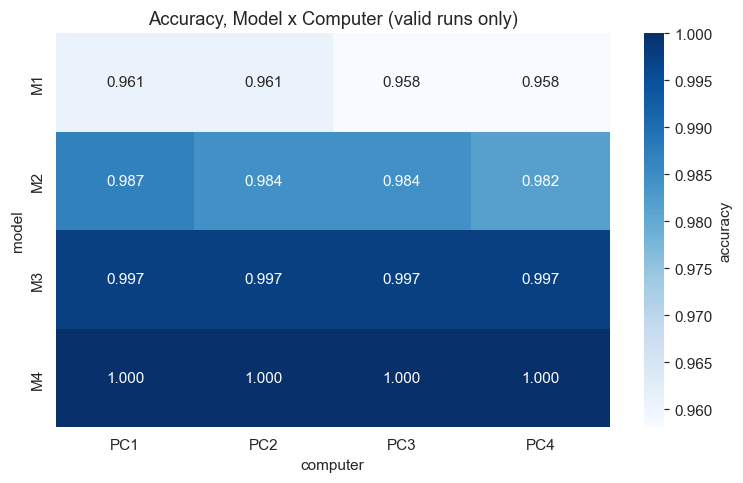

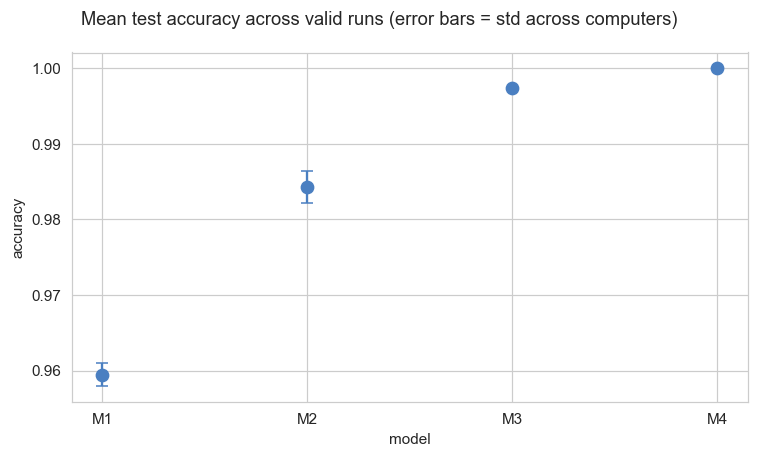

In [ ]:
ALL_METRICS_ROWS = []
for eid in sorted(VALID_RUNS):
    m, pc = eid.split("_")
    row = TEST_METRICS.get(eid)
    if row is None:
        continue
    ALL_METRICS_ROWS.append({"run_id": eid, "model": m, "computer": pc,
                             "accuracy": float(row["Accuracy"]), "precision": float(row["Precision"]),
                             "recall": float(row["Recall"]), "f1": float(row["F1"]), "test_loss": float(row["Test loss"])})
all_results_df = pd.DataFrame(ALL_METRICS_ROWS)

if len(all_results_df) == 0:
    print("No valid runs with test metrics - nothing to compare yet.")
else:
    pivot_acc = all_results_df.pivot(index="model", columns="computer", values="accuracy").reindex(index=MODEL_IDS, columns=COMPUTER_IDS)
    print("Accuracy, Model x Computer (valid runs only):")
    print(pivot_acc.round(4).to_string())

    summary_rows = []
    for m, g in all_results_df.groupby("model"):
        for metric in ["accuracy", "precision", "recall", "f1"]:
            summary_rows.append({"model": m, "metric": metric, "n_runs": len(g), "mean": g[metric].mean(),
                                 "std": g[metric].std(), "min": g[metric].min(), "max": g[metric].max(),
                                 "range": g[metric].max() - g[metric].min()})
    model_comparison_df = pd.DataFrame(summary_rows)
    print("\nPer-model summary statistics (across valid runs):")
    print(model_comparison_df[model_comparison_df["metric"] == "accuracy"].round(4).to_string(index=False))

    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(pivot_acc, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar_kws={"label": "accuracy"})
    ax.set_title("Accuracy, Model x Computer (valid runs only)")
    ax.set_xlabel("computer"); ax.set_ylabel("model")
    fig.tight_layout()
    save_fig(fig, "accuracy_by_model")

    acc_summary = model_comparison_df[model_comparison_df["metric"] == "accuracy"].set_index("model").reindex(MODEL_IDS)
    fig2, ax2 = plt.subplots(figsize=(7, 4.2))
    ax2.errorbar(MODEL_IDS, acc_summary["mean"], yerr=acc_summary["std"], marker="o", markersize=8,
                capsize=4, linestyle="none", color="#4a7fc1")
    ax2.set_ylabel("accuracy"); ax2.set_xlabel("model")
    fig2.suptitle("Mean test accuracy across valid runs (error bars = std across computers)", fontsize=12)
    fig2.tight_layout()
    save_fig(fig2, "accuracy_by_model_dotplot")

    all_results_df.to_csv(f"{DIRS['tables']}/all_experiment_results.csv", index=False)
    model_comparison_df.to_csv(f"{DIRS['tables']}/model_comparison_summary.csv", index=False)
    pivot_acc.to_csv(f"{DIRS['tables']}/accuracy_by_model_and_computer.csv")

## 6. Confusion Matrices & Learning Behaviour
Each computer already rendered its own confusion matrices and learning curves (Notebook 1 Sections 12.1/12.2) - this section displays them side by side for comparison rather than re-deriving them from raw predictions, and reads the saved per-epoch history to compare convergence and overfitting signs across computers for the same model.

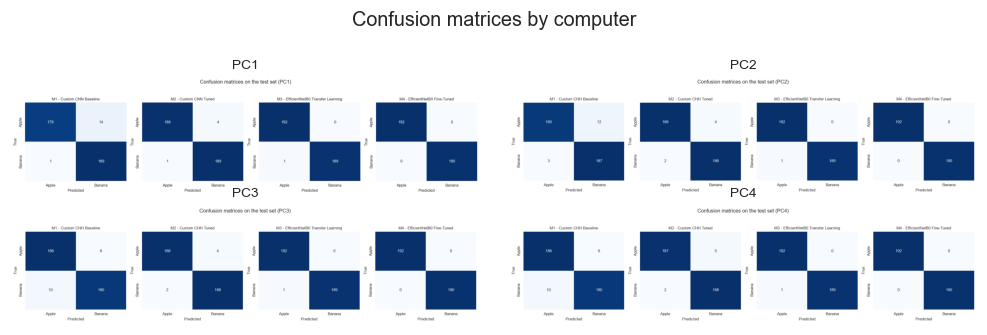

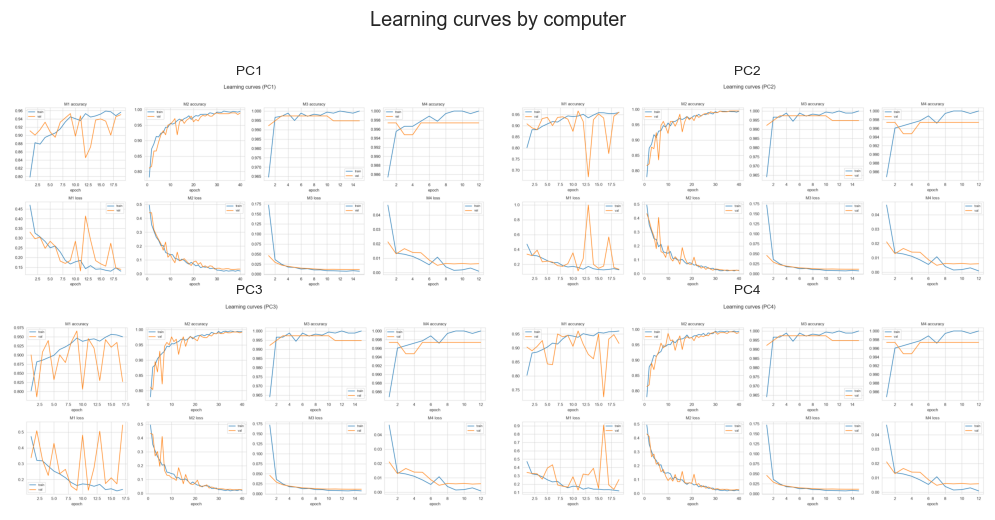

In [ ]:
def show_images_grid(paths_with_labels, title, ncols=4):
    """paths_with_labels: list of (path, caption). Skips any path that doesn't exist, with a note.
    Each cell's height is sized to the actual image's aspect ratio (most of these source PNGs are
    wide and short - a fixed square-ish cell was leaving large empty margins above/below them)."""
    present = [(p, c) for p, c in paths_with_labels if os.path.exists(p)]
    missing = [c for p, c in paths_with_labels if not os.path.exists(p)]
    if not present:
        print(f"{title}: no images found to show.")
        return
    nrows = int(np.ceil(len(present) / ncols))
    sample = mpimg.imread(present[0][0])
    img_aspect = sample.shape[1] / sample.shape[0]           # width / height, in pixels
    cell_width = 4.6
    cell_height = cell_width / img_aspect + 0.35              # + a little room for the per-image caption
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_width * ncols, cell_height * nrows))
    axes = np.atleast_1d(axes).flatten()
    for ax, (p, caption) in zip(axes, present):
        ax.imshow(mpimg.imread(p)); ax.axis("off"); ax.set_title(caption, fontsize=9)
    for ax in axes[len(present):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, y=0.995)
    fig.subplots_adjust(wspace=0.04, hspace=0.12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    save_fig(fig, title.lower().replace(" ", "_").replace("/", "_"))
    if missing:
        print(f"  (missing: {missing})")

cm_paths = [(f"{PC_DIRS[pc]}/confusion_matrices/confusion_matrices_{pc}.png", pc)
           for pc in COMPUTER_IDS if pc in PC_DIRS]
show_images_grid(cm_paths, "Confusion matrices by computer", ncols=2)

lc_paths = [(f"{PC_DIRS[pc]}/learning_curves/learning_curves_{pc}.png", pc)
           for pc in COMPUTER_IDS if pc in PC_DIRS]
show_images_grid(lc_paths, "Learning curves by computer", ncols=2)

Convergence summary (valid runs):
run_id model computer  epochs_run  best_epoch  final_train_val_acc_gap  final_val_loss
M1_PC1    M1      PC1          19          11                   0.0059          0.1393
M1_PC2    M1      PC2          19          11                  -0.0017          0.1346
M1_PC3    M1      PC3          17           9                   0.1228          0.5444
M1_PC4    M1      PC4          19          11                   0.0444          0.2561
M2_PC1    M2      PC1          40          37                   0.0054          0.0346
M2_PC2    M2      PC2          40          36                  -0.0009          0.0248
M2_PC3    M2      PC3          40          36                   0.0011          0.0255
M2_PC4    M2      PC4          40          36                   0.0043          0.0268
M3_PC1    M3      PC1          15          10                   0.0052          0.0114
M3_PC2    M3      PC2          15          10                   0.0052          0.0115
M3_PC3   

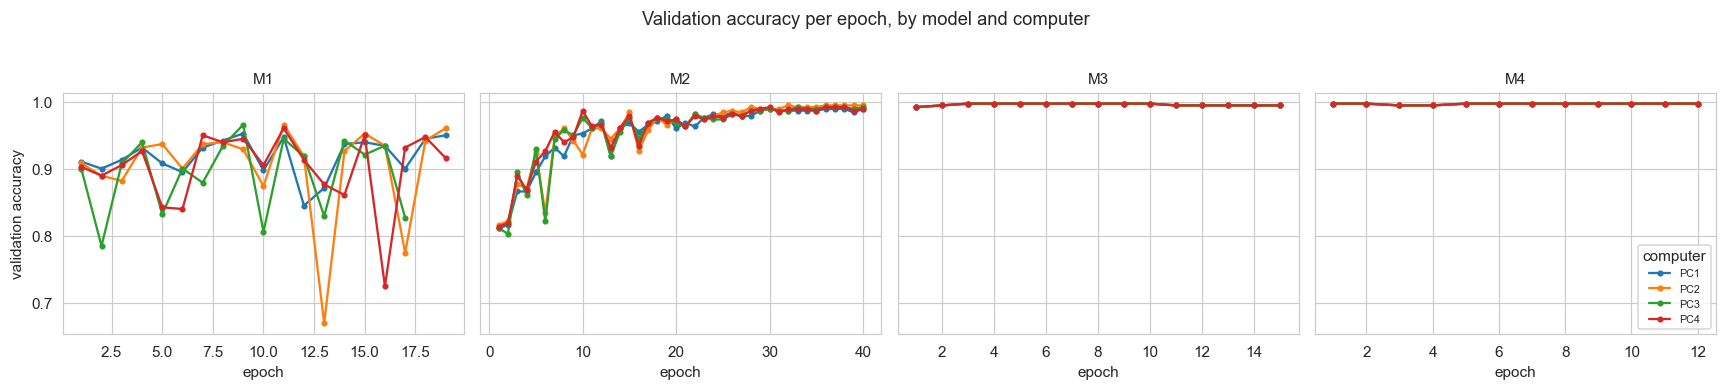

In [ ]:
# Convergence / overfitting signals straight from the saved per-epoch history
convergence_rows = []
for eid in sorted(VALID_RUNS):
    m, pc = eid.split("_")
    log = EXPERIMENT_LOGS.get(eid)
    if log is None or "history" not in log:
        continue
    h = log["history"]
    final_gap = h["train_acc"][-1] - h["val_acc"][-1] if h["train_acc"] and h["val_acc"] else float("nan")
    convergence_rows.append({"run_id": eid, "model": m, "computer": pc, "epochs_run": log.get("epochs"),
                             "best_epoch": log.get("best_epoch"), "final_train_val_acc_gap": final_gap,
                             "final_val_loss": h["val_loss"][-1] if h.get("val_loss") else float("nan")})
convergence_df = pd.DataFrame(convergence_rows)
if len(convergence_df):
    print("Convergence summary (valid runs):")
    print(convergence_df.round(4).to_string(index=False))
    overfit = convergence_df[convergence_df["final_train_val_acc_gap"] > 0.10]
    if len(overfit):
        print(f"\nWARNING!!! Train/val accuracy gap > 10% (possible overfitting) on: {list(overfit['run_id'])}")
    convergence_df.to_csv(f"{DIRS['tables']}/convergence_summary.csv", index=False)

    present_models = [m for m in MODEL_IDS if (convergence_df["model"] == m).any()]
    if present_models:
        fig, axes = plt.subplots(1, len(present_models), figsize=(4 * len(present_models), 3.4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, m in zip(axes, present_models):
            for eid in sorted(VALID_RUNS):
                mm, pc = eid.split("_")
                if mm != m:
                    continue
                log = EXPERIMENT_LOGS.get(eid)
                vacc = log["history"].get("val_acc") if log and "history" in log else None
                if vacc:
                    ax.plot(range(1, len(vacc) + 1), vacc, marker="o", markersize=3, label=pc)
            ax.set_title(m, fontsize=10); ax.set_xlabel("epoch")
        axes[0].set_ylabel("validation accuracy")
        axes[-1].legend(fontsize=7, loc="lower right", title="computer")
        fig.suptitle("Validation accuracy per epoch, by model and computer", y=1.03, fontsize=12)
        fig.tight_layout()
        save_fig(fig, "convergence_curves")

## 7. Model-by-Model Interpretation
Three specific questions, answered from the evidence gathered above rather than assumed in advance:

1. Did M2 (tuned) improve on M1 (baseline)?
2. Did transfer learning (M3) outperform the custom CNNs (M1, M2)?
3. Did fine-tuning (M4) improve on frozen-backbone transfer learning (M3)?

1. M2 (tuned) vs M1 (baseline):
   M2 (0.9843) improved on M1 (0.9594)  [diff +0.0249]

2. Transfer learning (M3) vs the better custom CNN (M1/M2):
   best custom CNN by mean accuracy: M2
   M3 (0.9974) improved on M2 (0.9843)  [diff +0.0131]

3. Fine-tuning (M4) vs frozen-backbone transfer learning (M3):
   M4 (1.0000) is essentially tied with M3 (0.9974)  [diff +0.0026]


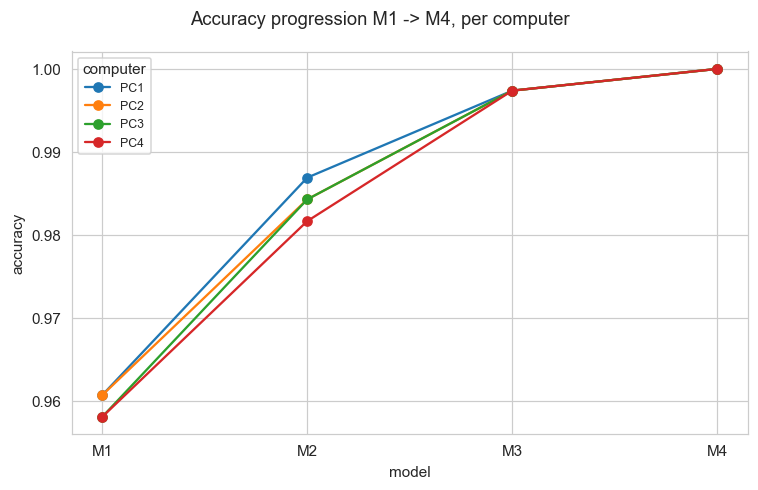

In [ ]:
def model_mean(metric, model_id):
    sub = all_results_df[all_results_df["model"] == model_id]
    return float(sub[metric].mean()) if len(sub) else float("nan")

def compare(a, b, metric="accuracy"):
    va, vb = model_mean(metric, a), model_mean(metric, b)
    if np.isnan(va) or np.isnan(vb):
        return f"{a} vs {b}: insufficient valid runs to compare"
    diff = va - vb
    verdict = "improved on" if diff > 0.005 else ("is essentially tied with" if abs(diff) <= 0.005 else "is worse than")
    return f"{a} ({va:.4f}) {verdict} {b} ({vb:.4f})  [diff {diff:+.4f}]"

print("1. M2 (tuned) vs M1 (baseline):")
print("   " + compare("M2", "M1"))
print("\n2. Transfer learning (M3) vs the better custom CNN (M1/M2):")
best_custom = "M2" if model_mean("accuracy", "M2") >= model_mean("accuracy", "M1") else "M1"
print(f"   best custom CNN by mean accuracy: {best_custom}")
print("   " + compare("M3", best_custom))
print("\n3. Fine-tuning (M4) vs frozen-backbone transfer learning (M3):")
print("   " + compare("M4", "M3"))

interpretation_notes = {
    "m2_vs_m1": compare("M2", "M1"), "m3_vs_best_custom": compare("M3", best_custom), "m4_vs_m3": compare("M4", "M3"),
}
with open(f"{DIRS['tables']}/model_interpretation.json", "w") as f:
    json.dump(interpretation_notes, f, indent=2)

if len(all_results_df):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for pc in COMPUTER_IDS:
        sub_pc = all_results_df[all_results_df["computer"] == pc].set_index("model").reindex(MODEL_IDS)
        if sub_pc["accuracy"].notna().any():
            ax.plot(MODEL_IDS, sub_pc["accuracy"], marker="o", label=pc)
    ax.set_ylabel("accuracy"); ax.set_xlabel("model")
    ax.legend(fontsize=8, title="computer")
    fig.suptitle("Accuracy progression M1 -> M4, per computer", fontsize=12)
    fig.tight_layout()
    save_fig(fig, "model_progression")

#### Reasoning: A Tie Band, Not Just a Sign Check
A raw `diff > 0` would call a 0.0003 accuracy difference an "improvement", which is noise, not evidence, given the spread already visible in Section 5's per-computer numbers. The ±0.5 percentage-point band above treats anything smaller as a tie; Section 17 adds variability across computers on top of this for a more careful read before Section 18 commits to a final answer.

## 8. Cross-Computer Reproducibility
Performance, training time, convergence and environment, side by side across PC1–PC4. **Four computers alone do not establish that a model generalises to new data** - this section is about whether the *same* training run behaves consistently across *environments*, which is a narrower and different claim.

Environment by computer:
Computer         OS    PyTorch Device                                                  CPU  RAM (GB)  Threads used Dataset fingerprint  Config hash
     PC1 Windows 11  2.7.1+cpu    cpu Intel64 Family 6 Model 142 Stepping 10, GenuineIntel      34.2             4    52b395cdef84b0ff d7e2e21cf167
     PC2 Windows 10 2.14.1+cpu    cpu       11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz       8.3             4    52b395cdef84b0ff d7e2e21cf167
     PC3 Windows 11 2.14.1+cpu    cpu  Intel64 Family 6 Model 186 Stepping 2, GenuineIntel      16.9            10    52b395cdef84b0ff d7e2e21cf167
     PC4 Windows 11 2.14.1+cpu    cpu             Intel(R) Core(TM) i7-8650U CPU @ 1.90GHz      17.0             4    52b395cdef84b0ff d7e2e21cf167

Training time (s), Model x Computer:
computer     PC1     PC2     PC3     PC4
model                                   
M1        1122.0   907.0   331.0  1344.0
M2        5623.0  4052.0  1815.0  6094.0
M3         457.0   376.0   157.0 

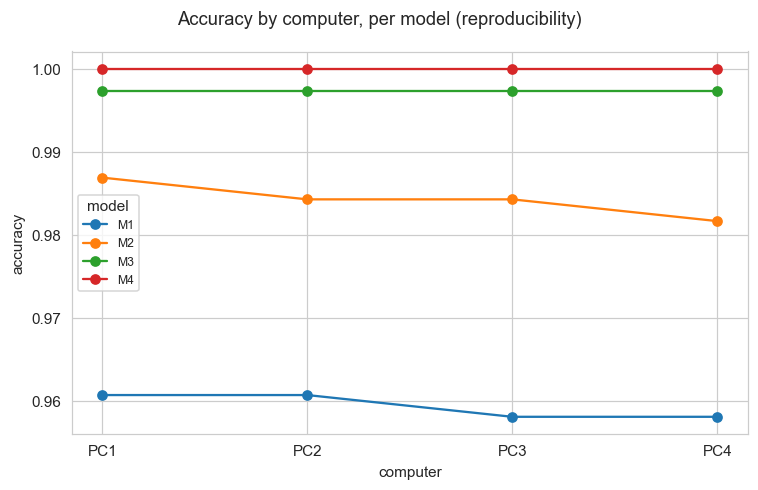

In [ ]:
env_rows = []
for pc, d in PC_DIRS.items():
    env_df = read_csv(f"{d}/reproducibility/environment_{pc}.csv")
    if env_df is not None:
        env_rows.append(env_df.iloc[0].to_dict())
env_comparison_df = pd.DataFrame(env_rows)
print("Environment by computer:")
print(env_comparison_df.to_string(index=False) if len(env_comparison_df) else "  (none found)")

time_rows = [{"model": eid.split("_")[0], "computer": eid.split("_")[1], "train_time_s": EXPERIMENT_LOGS[eid].get("train_time_s")}
            for eid in sorted(VALID_RUNS) if eid in EXPERIMENT_LOGS]
time_df = pd.DataFrame(time_rows)
if len(time_df):
    pivot_time = time_df.pivot(index="model", columns="computer", values="train_time_s").reindex(index=MODEL_IDS, columns=COMPUTER_IDS)
    print("\nTraining time (s), Model x Computer:")
    print(pivot_time.round(0).to_string())
else:
    pivot_time = pd.DataFrame()

if len(all_results_df):
    spread = all_results_df.groupby("model")["accuracy"].agg(lambda s: s.max() - s.min()).reindex(MODEL_IDS)
    print("\nAccuracy spread (max - min) per model across computers:")
    print(spread.round(4).to_string())
    high_spread = spread[spread > 0.03]
    if len(high_spread):
        print(f"\nWARNING!!! Spread > 3% for: {list(high_spread.index)} - compare the environment table above (OS/PyTorch/CPU) ")
        print("  before assuming this is a real training difference rather than a hardware/software one.")

env_comparison_df.to_csv(f"{DIRS['tables']}/reproducibility_summary.csv", index=False)
if len(pivot_time):
    pivot_time.to_csv(f"{DIRS['tables']}/train_time_by_model_and_computer.csv")

if len(all_results_df):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for m in MODEL_IDS:
        sub_m = all_results_df[all_results_df["model"] == m].set_index("computer").reindex(COMPUTER_IDS)
        if sub_m["accuracy"].notna().any():
            ax.plot(COMPUTER_IDS, sub_m["accuracy"], marker="o", label=m)
    ax.set_ylabel("accuracy"); ax.set_xlabel("computer")
    ax.legend(fontsize=8, title="model")
    fig.suptitle("Accuracy by computer, per model (reproducibility)", fontsize=12)
    fig.tight_layout()
    save_fig(fig, "reproducibility_by_computer")

#### Reasoning: Separating Hardware Effects from Real Differences
A large accuracy spread for one model and a tight spread for the others is a *different* finding from a large spread across every model: the former points at that one model's training being sensitive to something environment-specific (thread count, a library version), the latter points at something systemic (all four computers really did train somewhat differently, or the comparison basis itself - Section 3/4 - is shakier than it looked). The environment table exists specifically so that distinction doesn't have to be guessed at.

## 9. Error Analysis
Misclassification records combined across every valid run, broken down by model, computer and source. As in Notebook 1, **this notebook cannot label "poor lighting" or "occlusion" on its own** - the representative image grids below (already rendered by Notebook 1) are for a human reviewer to look for those patterns.

Combined misclassifications across valid runs: 90

By model:
model
M1    62
M2    24
M3     4
M4     0

By model x source:
source  Public  Student
model                  
M1        28.0     34.0
M2        24.0      0.0
M3         4.0      0.0
M4         NaN      NaN

Mean confidence on wrong predictions: 0.710


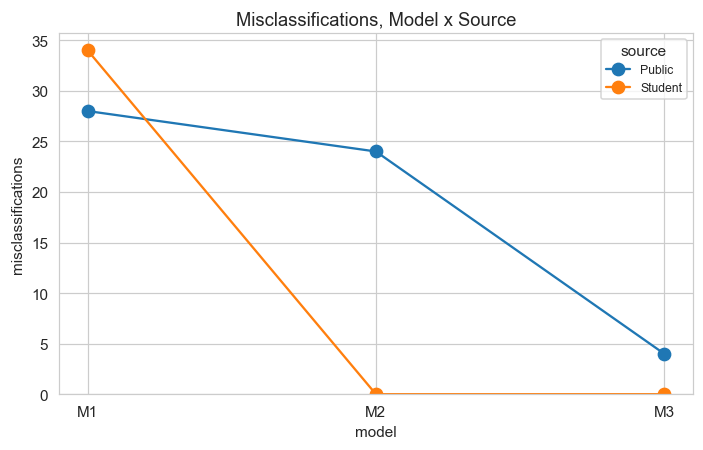

In [ ]:
error_dfs = []
for eid in sorted(VALID_RUNS):
    m, pc = eid.split("_")
    df = read_csv(f"{PC_DIRS[pc]}/error_analysis/{eid}_errors.csv")
    if df is not None:
        df = df.copy(); df["model"] = m; df["computer"] = pc
        error_dfs.append(df)

if error_dfs:
    combined_errors_df = pd.concat(error_dfs, ignore_index=True)
    print(f"Combined misclassifications across valid runs: {len(combined_errors_df)}")
    print("\nBy model:")
    print(combined_errors_df.groupby("model").size().reindex(MODEL_IDS, fill_value=0).to_string())
    if "source" in combined_errors_df.columns:
        print("\nBy model x source:")
        print(combined_errors_df.groupby(["model", "source"]).size().unstack(fill_value=0).reindex(MODEL_IDS).to_string())
    print(f"\nMean confidence on wrong predictions: {combined_errors_df['confidence'].mean():.3f}")
    combined_errors_df.to_csv(f"{DIRS['tables']}/error_analysis.csv", index=False)

    if "source" in combined_errors_df.columns:
        pivot_err = combined_errors_df.groupby(["model", "source"]).size().unstack(fill_value=0).reindex(MODEL_IDS)
        if pivot_err.shape[1]:
            fig, ax = plt.subplots(figsize=(6.5, 4.2))
            for src in pivot_err.columns:
                ax.plot(pivot_err.index, pivot_err[src], marker="o", markersize=8, label=src)
            ax.set_ylabel("misclassifications"); ax.set_xlabel("model")
            ax.set_ylim(bottom=0)
            ax.legend(fontsize=8, title="source")
            ax.set_title("Misclassifications, Model x Source")
            fig.tight_layout()
            save_fig(fig, "error_by_source")
else:
    combined_errors_df = pd.DataFrame()
    print("No error_analysis files found among valid runs.")

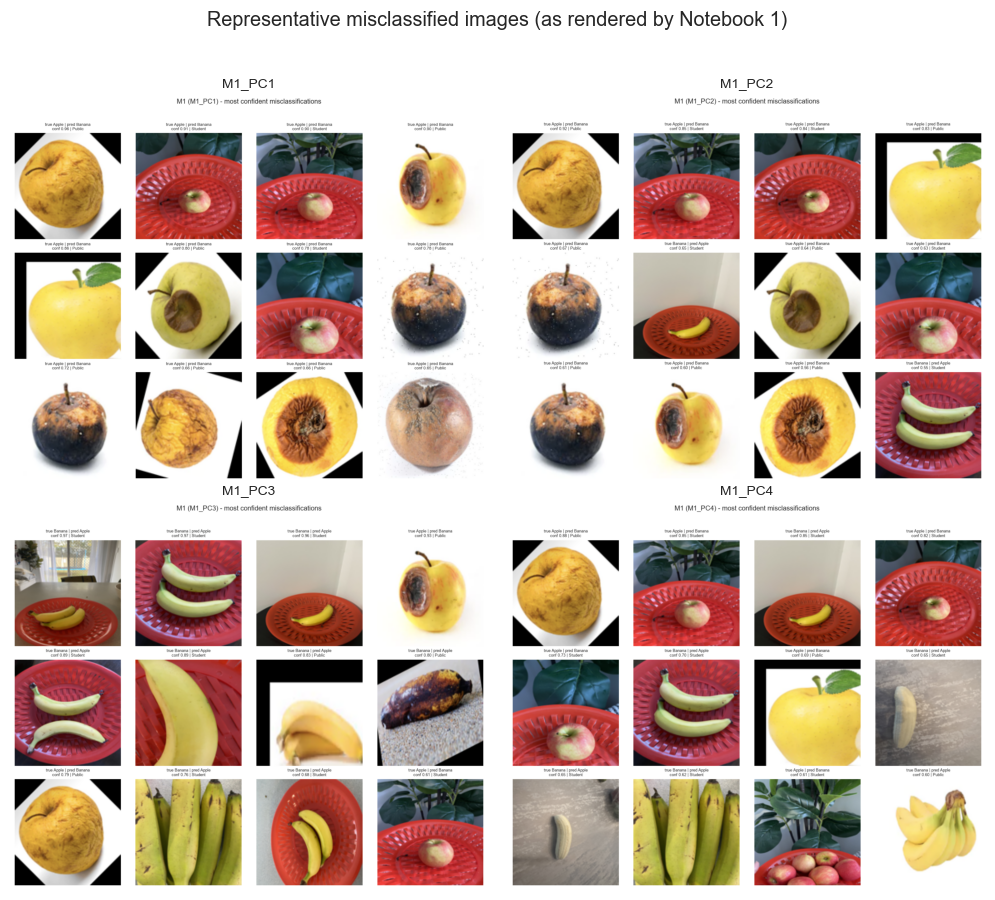

In [ ]:
example_paths = [(p, os.path.basename(p).split("_misclassified")[0])
                 for d in PC_DIRS.values() for p in glob.glob(f"{d}/error_analysis/*_misclassified_examples.png")]
show_images_grid(example_paths, "Representative misclassified images (as rendered by Notebook 1)", ncols=2)

## 10. Student-versus-Public Generalisation
Each model's accuracy on the student-sourced and public-sourced halves of the test set, averaged across valid runs. **These are subgroup results on one 382-image test set, not proof of generalisation to sources outside it.**

Mean accuracy by source (averaged across valid runs):
source  Public  Student     gap
model                          
M1      0.9634   0.9555  0.0079
M2      0.9686   1.0000  0.0314
M3      0.9948   1.0000  0.0052
M4      1.0000   1.0000  0.0000

Subgroup sizes: {'Public': 191, 'Student': 191}


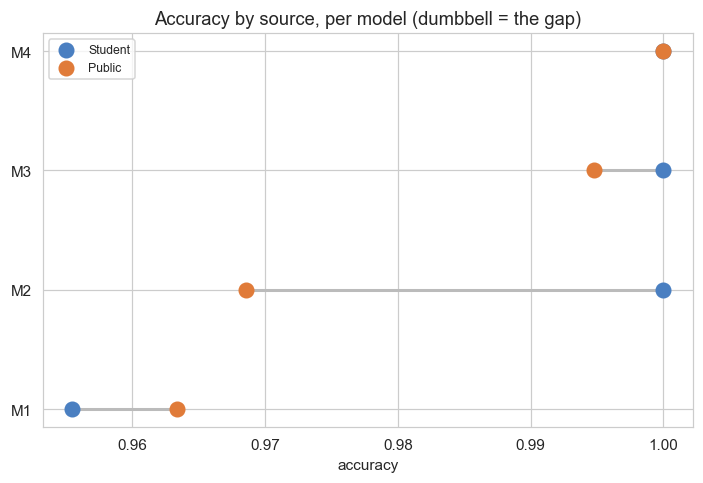

In [ ]:
source_dfs = []
for eid in sorted(VALID_RUNS):
    m, pc = eid.split("_")
    df = read_csv(f"{PC_DIRS[pc]}/metrics/student_vs_public_{pc}.csv")
    if df is not None:
        df = df[df["Model"] == m].copy()
        df["computer"] = pc
        source_dfs.append(df)

if source_dfs:
    source_generalisation_df = pd.concat(source_dfs, ignore_index=True).rename(columns={"Model": "model", "Source": "source"})
    pivot = source_generalisation_df.groupby(["model", "source"])["Accuracy"].mean().unstack().reindex(MODEL_IDS)
    pivot["gap"] = (pivot.get("Student", np.nan) - pivot.get("Public", np.nan)).abs()
    print("Mean accuracy by source (averaged across valid runs):")
    print(pivot.round(4).to_string())
    if (pivot["gap"] > 0.05).any():
        print(f"\nWARNING!!! Student/Public gap > 5% for: {list(pivot[pivot['gap'] > 0.05].index)}")
    sizes = source_generalisation_df.groupby("source")["n"].first()
    print(f"\nSubgroup sizes: {sizes.to_dict()}")
    source_generalisation_df.to_csv(f"{DIRS['tables']}/source_generalisation_results.csv", index=False)

    heat_cols = [c for c in ["Student", "Public"] if c in pivot.columns]
    if len(heat_cols) == 2:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        y_pos = np.arange(len(MODEL_IDS))
        for y, m in zip(y_pos, MODEL_IDS):
            if m not in pivot.index or pivot.loc[m, heat_cols].isna().any():
                continue
            xs = pivot.loc[m, heat_cols].values
            ax.plot(xs, [y, y], color="#bbbbbb", zorder=1, linewidth=2)
            ax.scatter(xs[0], y, s=90, color="#4a7fc1", zorder=2, label="Student" if y == 0 else None)
            ax.scatter(xs[1], y, s=90, color="#e07b39", zorder=2, label="Public" if y == 0 else None)
        ax.set_yticks(y_pos); ax.set_yticklabels(MODEL_IDS)
        ax.set_xlabel("accuracy")
        ax.legend(fontsize=8)
        ax.set_title("Accuracy by source, per model (dumbbell = the gap)")
        fig.tight_layout()
        save_fig(fig, "source_generalisation_dumbbell")
else:
    source_generalisation_df = pd.DataFrame()
    print("No student_vs_public files found among valid runs.")

## 11. Confidence & Reliability Analysis
Confidence-vs-correctness buckets (correct/incorrect x high/low confidence, against Notebook 1's fixed `CONFIDENCE_THRESHOLD = 0.90`), averaged across valid runs. **Calibration and accuracy are different questions** - a model can be accurate yet poorly calibrated (confident when wrong), or well calibrated yet mediocre; `incorrect_high` (confidently wrong) is the bucket that matters most for a deployed confidence gate.

       correct_high  correct_low  incorrect_high  incorrect_low  mean_conf_correct  mean_conf_incorrect  roc_auc
model                                                                                                           
M1           289.75        76.75            1.75          13.75              0.935                0.714    0.992
M2           365.00        11.00            0.00           6.00              0.989                0.697    1.000
M3           376.25         4.75            0.00           1.00              0.994                0.721    1.000
M4           382.00         0.00            0.00           0.00              0.999                  NaN    1.000

WARNING!!! Confidently-wrong predictions occur for: ['M1']


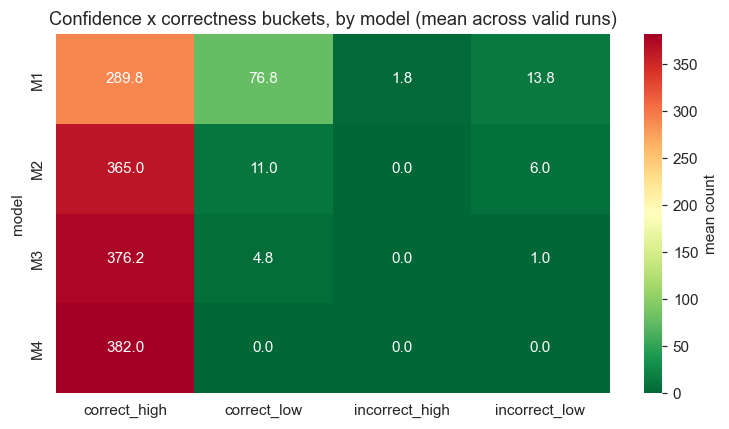

In [ ]:
if HAVE["reliability"]:
    rel_dfs = []
    for eid in sorted(VALID_RUNS):
        m, pc = eid.split("_")
        df = read_csv(f"{PC_DIRS[pc]}/reliability/reliability_summary_{pc}.csv")
        if df is not None:
            row = df[df["Model"] == m]
            if len(row):
                row = row.copy(); row["computer"] = pc
                rel_dfs.append(row)
    if rel_dfs:
        confidence_analysis_df = pd.concat(rel_dfs, ignore_index=True).rename(columns={"Model": "model"})
        cols = ["correct_high", "correct_low", "incorrect_high", "incorrect_low", "mean_conf_correct", "mean_conf_incorrect", "roc_auc"]
        print(confidence_analysis_df.groupby("model")[cols].mean().round(3).to_string())
        high_conf_wrong = confidence_analysis_df[confidence_analysis_df["incorrect_high"] > 0]
        if len(high_conf_wrong):
            print(f"\nWARNING!!! Confidently-wrong predictions occur for: {sorted(set(high_conf_wrong['model']))}")
        confidence_analysis_df.to_csv(f"{DIRS['tables']}/confidence_analysis.csv", index=False)

        bucket_cols = ["correct_high", "correct_low", "incorrect_high", "incorrect_low"]
        bucket_means = confidence_analysis_df.groupby("model")[bucket_cols].mean().reindex(MODEL_IDS)
        fig, ax = plt.subplots(figsize=(7, 4))
        sns.heatmap(bucket_means, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=ax, cbar_kws={"label": "mean count"})
        ax.set_title("Confidence x correctness buckets, by model (mean across valid runs)")
        fig.tight_layout()
        save_fig(fig, "confidence_buckets_heatmap")
    else:
        confidence_analysis_df = pd.DataFrame()
        print("No reliability summaries found among valid runs.")
else:
    confidence_analysis_df = pd.DataFrame()
    print("No reliability outputs found in any result file - Section 11 skipped.")

## 12. Feature-Space Analysis [STRETCH]
Raw embeddings aren't combined across computers here - two independently-trained copies of the same architecture do not share a feature space, so their embeddings aren't directly comparable even if the architecture is identical. What *is* comparable is each run's own already-computed summary: how far correct/incorrect and low/high-confidence test images sit from that model's own training-class centroids (Notebook 1 Section 16), and the PCA snapshots side by side.

Feature-space data found for 4/4 computers: ['PC1', 'PC2', 'PC3', 'PC4']
       mean_dist_correct  mean_dist_incorrect  mean_dist_low_conf  mean_dist_high_conf
model                                                                                 
M1                10.247               13.508              10.573               10.346
M2                12.830               13.825              15.194               12.736
M3                41.618               61.539              67.316               41.278
M4                41.615                  NaN                 NaN               41.615


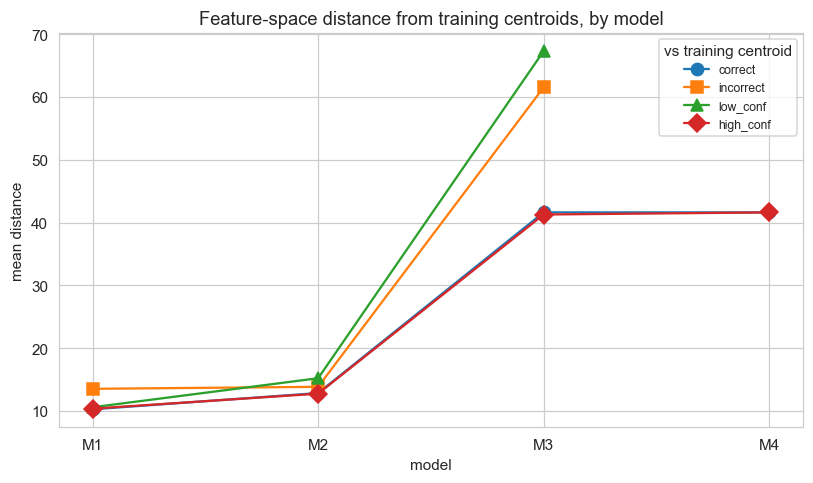

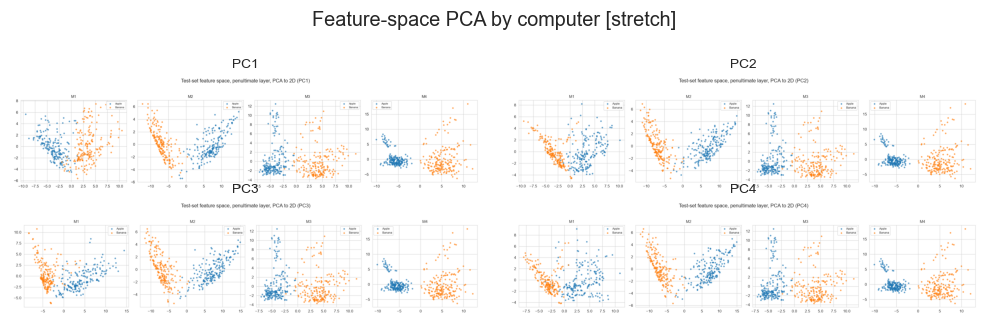

In [ ]:
if HAVE["embeddings"]:
    fd_dfs = []
    for pc, d in PC_DIRS.items():
        df = read_csv(f"{d}/embeddings/feature_distance_summary_{pc}.csv")
        if df is not None:
            df = df.copy(); df["computer"] = pc
            fd_dfs.append(df)
    computers_with_data = sorted({pc for pc, d in PC_DIRS.items() if os.path.exists(f"{d}/embeddings/feature_distance_summary_{pc}.csv")})
    print(f"Feature-space data found for {len(computers_with_data)}/{len(PC_DIRS)} computers: {computers_with_data}")
    if len(computers_with_data) < len(PC_DIRS):
        print(f"  Missing from: {sorted(set(PC_DIRS) - set(computers_with_data))} - either RUN_STRETCH was off there, or")
        print("  that computer's results folder genuinely doesn't contain embeddings/ (not a Notebook 2 filtering issue).")

    if fd_dfs:
        feature_space_df = pd.concat(fd_dfs, ignore_index=True).rename(columns={"Model": "model"})
        feature_space_df = feature_space_df[[f"{r.model}_{r.computer}" in VALID_RUNS for r in feature_space_df.itertuples()]]
        cols = ["mean_dist_correct", "mean_dist_incorrect", "mean_dist_low_conf", "mean_dist_high_conf"]
        print(feature_space_df.groupby("model")[cols].mean().round(3).to_string())
        feature_space_df.to_csv(f"{DIRS['tables']}/feature_space_summary.csv", index=False)

        dist_means = feature_space_df.groupby("model")[cols].mean().reindex(MODEL_IDS)
        fig, ax = plt.subplots(figsize=(7.5, 4.5))
        markers = ["o", "s", "^", "D"]
        for col, mk in zip(cols, markers):
            ax.plot(dist_means.index, dist_means[col], marker=mk, markersize=8, label=col.replace("mean_dist_", ""))
        ax.set_ylabel("mean distance"); ax.set_xlabel("model")
        ax.legend(fontsize=8, title="vs training centroid")
        ax.set_title("Feature-space distance from training centroids, by model")
        fig.tight_layout()
        save_fig(fig, "feature_distance_by_model")
    pca_paths = [(f"{d}/embeddings/feature_space_pca_{pc}.png", pc) for pc, d in PC_DIRS.items()]
    show_images_grid(pca_paths, "Feature-space PCA by computer [stretch]", ncols=2)
else:
    print("No embeddings/feature-space outputs found in any result file - Section 12 skipped.")

## 13. Test-Time Augmentation [STRETCH]
How often each model's prediction flips under Notebook 1's five TTA views (flip, ±10° rotation, brightened), averaged across valid runs. A high flip rate on realistic, mild transforms is a reliability signal independent of raw softmax confidence.

TTA data found for 4/4 computers: ['PC1', 'PC2', 'PC3', 'PC4']
model
M1    0.075
M2    0.029
M3    0.000
M4    0.000


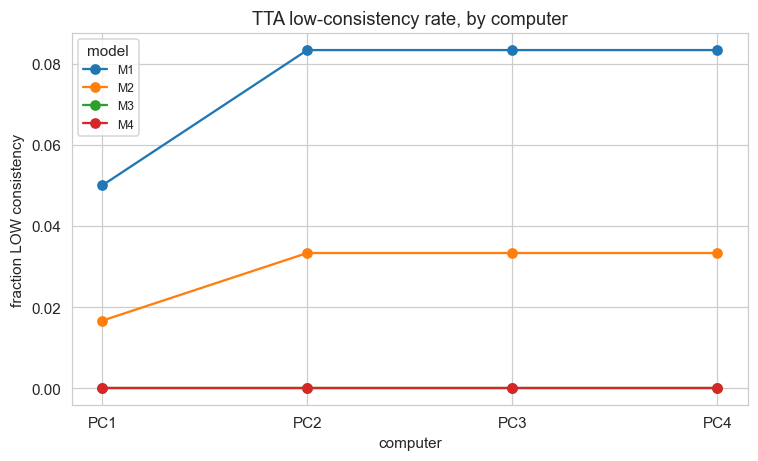

In [ ]:
if HAVE["tta"]:
    computers_with_tta = sorted(pc for pc, d in PC_DIRS.items()
                                if any(os.path.exists(f"{d}/tta/{m}_{pc}_tta.csv") for m in MODEL_IDS))
    print(f"TTA data found for {len(computers_with_tta)}/{len(PC_DIRS)} computers: {computers_with_tta}")
    if len(computers_with_tta) < len(PC_DIRS):
        print(f"  Missing from: {sorted(set(PC_DIRS) - set(computers_with_tta))}")
    tta_rows = []
    for eid in sorted(VALID_RUNS):
        m, pc = eid.split("_")
        df = read_csv(f"{PC_DIRS[pc]}/tta/{eid}_tta.csv")
        if df is not None and "consistency" in df.columns:
            tta_rows.append({"model": m, "computer": pc, "n_sampled": len(df),
                             "frac_low_consistency": float((df["consistency"] == "LOW").mean())})
    if tta_rows:
        tta_summary_df = pd.DataFrame(tta_rows)
        print(tta_summary_df.groupby("model")["frac_low_consistency"].mean().round(3).to_string())
        tta_summary_df.to_csv(f"{DIRS['tables']}/tta_summary.csv", index=False)

        pivot_tta = tta_summary_df.pivot(index="model", columns="computer", values="frac_low_consistency").reindex(index=MODEL_IDS, columns=COMPUTER_IDS)
        fig, ax = plt.subplots(figsize=(7, 4.3))
        for m in MODEL_IDS:
            if m in pivot_tta.index and pivot_tta.loc[m].notna().any():
                ax.plot(pivot_tta.columns, pivot_tta.loc[m], marker="o", label=m)
        ax.set_ylabel("fraction LOW consistency"); ax.set_xlabel("computer")
        ax.legend(fontsize=8, title="model")
        ax.set_title("TTA low-consistency rate, by computer")
        fig.tight_layout()
        save_fig(fig, "tta_consistency_by_computer")
    else:
        tta_summary_df = pd.DataFrame()
        print("No TTA files found among valid runs.")
else:
    tta_summary_df = pd.DataFrame()
    print("No TTA outputs found in any result file - Section 13 skipped.")

## 14. Unsupported-Input / OOD Analysis [STRETCH]
Acceptance/rejection rates on whichever `OOD_Examples` images each computer validated against (Notebook 1 Section 18), averaged across valid runs. **This only describes behaviour on the specific OOD images used** - see the reasoning note below before treating it as a general OOD-detection guarantee.

OOD example results found for 2/4 computers: ['PC1', 'PC2']
  Missing from: ['PC3', 'PC4'] - that computer's Notebook 1 run either had
  RUN_STRETCH off, or no OOD_Examples/Metadata/ood_metadata.csv was present when it ran Section 18.
model
M1    0.075
M2    0.130
M3    0.000
M4    0.000


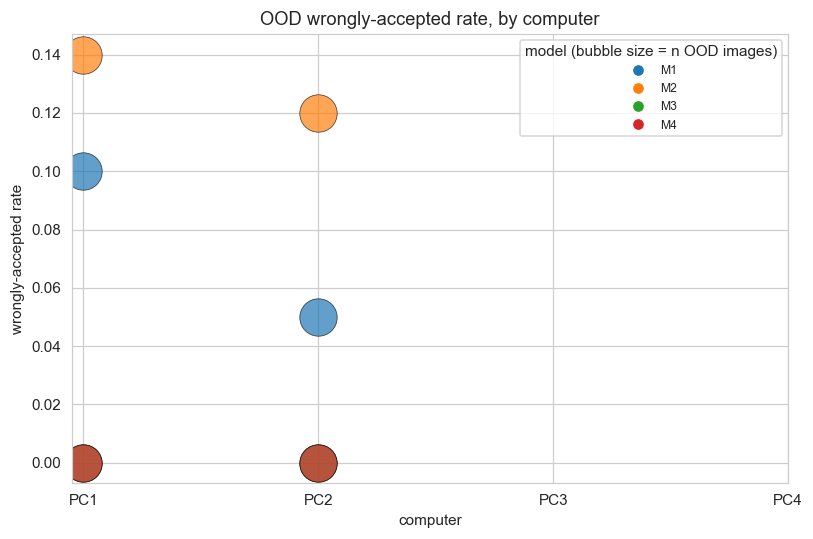

In [ ]:
if HAVE["ood"]:
    computers_with_ood = sorted({pc for pc, d in PC_DIRS.items() if os.path.exists(f"{d}/ood/ood_examples_results_{pc}.csv")})
    print(f"OOD example results found for {len(computers_with_ood)}/{len(PC_DIRS)} computers: {computers_with_ood}")
    if len(computers_with_ood) < len(PC_DIRS):
        print(f"  Missing from: {sorted(set(PC_DIRS) - set(computers_with_ood))} - that computer's Notebook 1 run either had")
        print("  RUN_STRETCH off, or no OOD_Examples/Metadata/ood_metadata.csv was present when it ran Section 18.")

    ood_rows = []
    for pc, d in PC_DIRS.items():
        df = read_csv(f"{d}/ood/ood_examples_results_{pc}.csv")
        if df is None:
            continue
        for m in MODEL_IDS:
            col = f"{m}_wrongly_accepted"
            if col in df.columns and f"{m}_{pc}" in VALID_RUNS:
                ood_rows.append({"model": m, "computer": pc, "n_ood_images": len(df),
                                 "wrongly_accepted": int(df[col].sum()), "rate": float(df[col].mean())})
    if ood_rows:
        ood_results_df = pd.DataFrame(ood_rows)
        print(ood_results_df.groupby("model")["rate"].mean().round(3).to_string())
        ood_results_df.to_csv(f"{DIRS['tables']}/ood_results.csv", index=False)

        fig, ax = plt.subplots(figsize=(7.5, 5))
        computer_x = {pc: i for i, pc in enumerate(COMPUTER_IDS)}
        model_colors = dict(zip(MODEL_IDS, sns.color_palette("tab10", len(MODEL_IDS))))
        for r in ood_results_df.itertuples():
            ax.scatter(computer_x[r.computer], r.rate, s=max(r.n_ood_images * 6, 40),
                      color=model_colors[r.model], alpha=0.7, edgecolor="black", linewidth=0.5)
        ax.set_xticks(list(computer_x.values())); ax.set_xticklabels(list(computer_x.keys()))
        ax.set_ylabel("wrongly-accepted rate"); ax.set_xlabel("computer")
        handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=model_colors[m], label=m) for m in MODEL_IDS]
        ax.legend(handles=handles, fontsize=8, title="model (bubble size = n OOD images)")
        ax.set_title("OOD wrongly-accepted rate, by computer")
        fig.tight_layout()
        save_fig(fig, "ood_bubble")
    else:
        ood_results_df = pd.DataFrame()
        print("No OOD example results found among valid runs.")
else:
    ood_results_df = pd.DataFrame()
    print("No OOD outputs found in any result file - Section 14 skipped.")

### 14.1 Robustness under extreme corruption (Notebook 1 Section 18.x)
Two stress tests Notebook 1 ran per model: an exact 90-degree rotation (no information lost, just reoriented - accuracy **should** hold up), and a sweep of {10,30,50,70,90}% random-noise corruption (information genuinely destroyed - confidence **should** fall below the gate, not stay high). Collated here the same way as everything else - valid runs only.

90-degree rotation: accuracy with vs without rotation, by model (averaged across valid runs):
       correct_original  correct_90
model                              
M1                0.946       0.854
M2                0.988       0.933
M3                1.000       1.000
M4                1.000       1.000

Mean confidence by noise level, by model (averaged across valid runs):
noise_level    0.1    0.3    0.5    0.7    0.9
model                                         
M1           0.891  0.967  0.968  0.976  0.979
M2           0.854  0.808  0.763  0.754  0.780
M3           0.989  0.944  0.769  0.581  0.549
M4           0.987  0.911  0.754  0.652  0.568


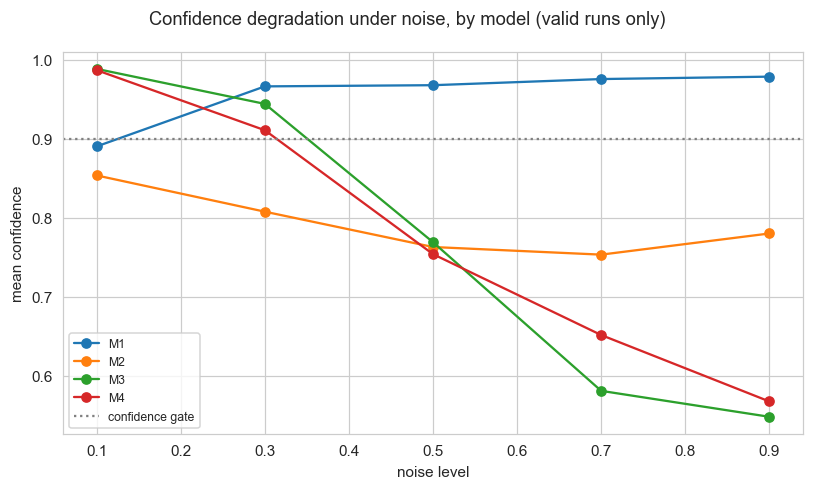

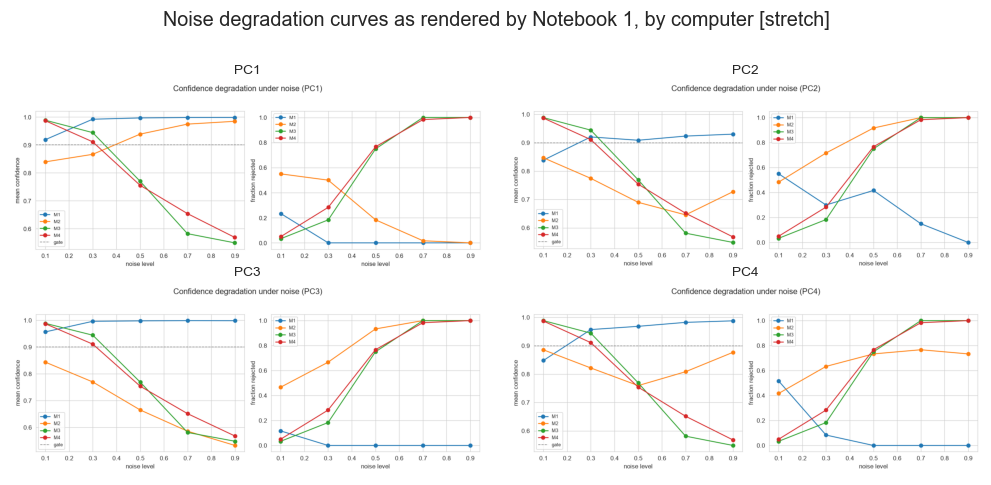

In [ ]:
rotation_dfs, noise_dfs = [], []
for eid in sorted(VALID_RUNS):
    m, pc = eid.split("_")
    rdf = read_csv(f"{PC_DIRS[pc]}/ood/{eid}_rotation_robustness.csv")
    if rdf is not None:
        rdf = rdf.copy(); rdf["model"] = m; rdf["computer"] = pc
        rotation_dfs.append(rdf)
    ndf = read_csv(f"{PC_DIRS[pc]}/ood/{eid}_noise_sweep.csv")
    if ndf is not None:
        ndf = ndf.copy(); ndf["model"] = m; ndf["computer"] = pc
        noise_dfs.append(ndf)

if rotation_dfs:
    robustness_rotation_df = pd.concat(rotation_dfs, ignore_index=True)
    robustness_rotation_df["correct_90"] = robustness_rotation_df["rotate_90_pred"] == robustness_rotation_df["true"]
    robustness_rotation_df["correct_original"] = robustness_rotation_df["original_pred"] == robustness_rotation_df["true"]
    rot_summary = robustness_rotation_df.groupby("model")[["correct_original", "correct_90"]].mean().reindex(MODEL_IDS)
    print("90-degree rotation: accuracy with vs without rotation, by model (averaged across valid runs):")
    print(rot_summary.round(3).to_string())
    robustness_rotation_df.to_csv(f"{DIRS['tables']}/robustness_rotation.csv", index=False)
else:
    robustness_rotation_df = pd.DataFrame()
    print("No rotation-robustness files found among valid runs.")

if noise_dfs:
    robustness_noise_df = pd.concat(noise_dfs, ignore_index=True)
    pivot_noise_conf = robustness_noise_df.groupby(["model", "noise_level"])["confidence"].mean().unstack().reindex(MODEL_IDS)
    print("\nMean confidence by noise level, by model (averaged across valid runs):")
    print(pivot_noise_conf.round(3).to_string())

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for m in MODEL_IDS:
        if m in pivot_noise_conf.index:
            ax.plot(pivot_noise_conf.columns, pivot_noise_conf.loc[m], marker="o", label=m)
    ax.axhline(CONFIDENCE_THRESHOLD, color="grey", linestyle=":", label="confidence gate")
    ax.set_xlabel("noise level"); ax.set_ylabel("mean confidence")
    ax.legend(fontsize=8)
    fig.suptitle("Confidence degradation under noise, by model (valid runs only)", fontsize=12)
    fig.tight_layout()
    save_fig(fig, "robustness_noise_degradation")
    robustness_noise_df.to_csv(f"{DIRS['tables']}/robustness_noise.csv", index=False)
else:
    robustness_noise_df = pd.DataFrame()
    print("No noise-sweep files found among valid runs.")

noise_paths = [(f"{d}/ood/noise_sweep_{pc}.png", pc) for pc, d in PC_DIRS.items()]
show_images_grid(noise_paths, "Noise degradation curves as rendered by Notebook 1, by computer [stretch]", ncols=2)

## 15. Combined Reliability Strategy [STRETCH]
Whether confidence, feature-space distance and TTA consistency together (Notebook 1 Section 18.y) provide a better cutoff than any one signal alone, collated across whichever computers ran that analysis.

Cutoff-analysis data found for 2/4 computers: ['PC1', 'PC2']
  Missing from: ['PC3', 'PC4'] - this means that computer's Notebook 1 Section 18.y never ran, which
  happens when RUN_STRETCH was off there, OR OOD_Examples/Metadata/ood_metadata.csv wasn't present/found
  on that computer at the time. Check those 2 computer(s)' own results/ood/ folder for
  cutoff_analysis_*.csv and ood_examples_results_*.csv to confirm which it was - this notebook is only
  showing what each computer's own submitted ZIP actually contains, not filtering anything out itself.
model           signal  configured_cutoff             recommended_cutoff    auc computer
   M1       confidence                0.9                         0.8986 0.5695      PC1
   M1 feature distance 14.514264106750488                        13.3452 0.9342      PC1
   M1  tta_consistency             != LOW test 5.0% LOW vs OOD 11.0% LOW    NaN      PC1
   M2       confidence                0.9                         0.9972 0.7887     

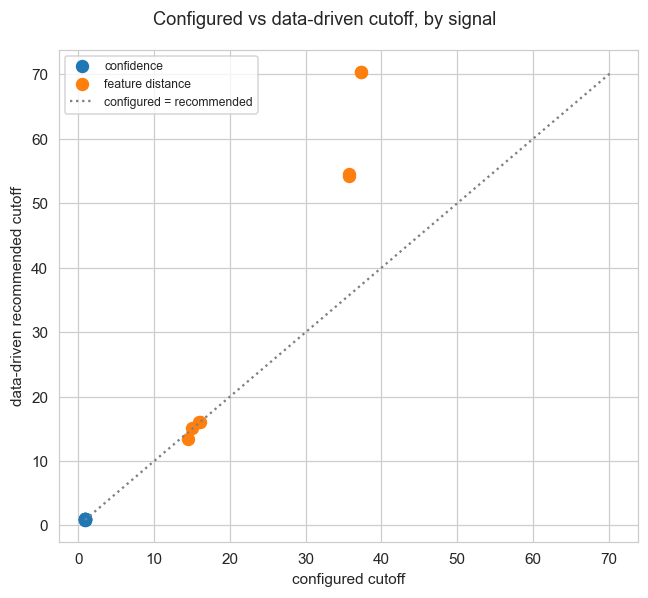

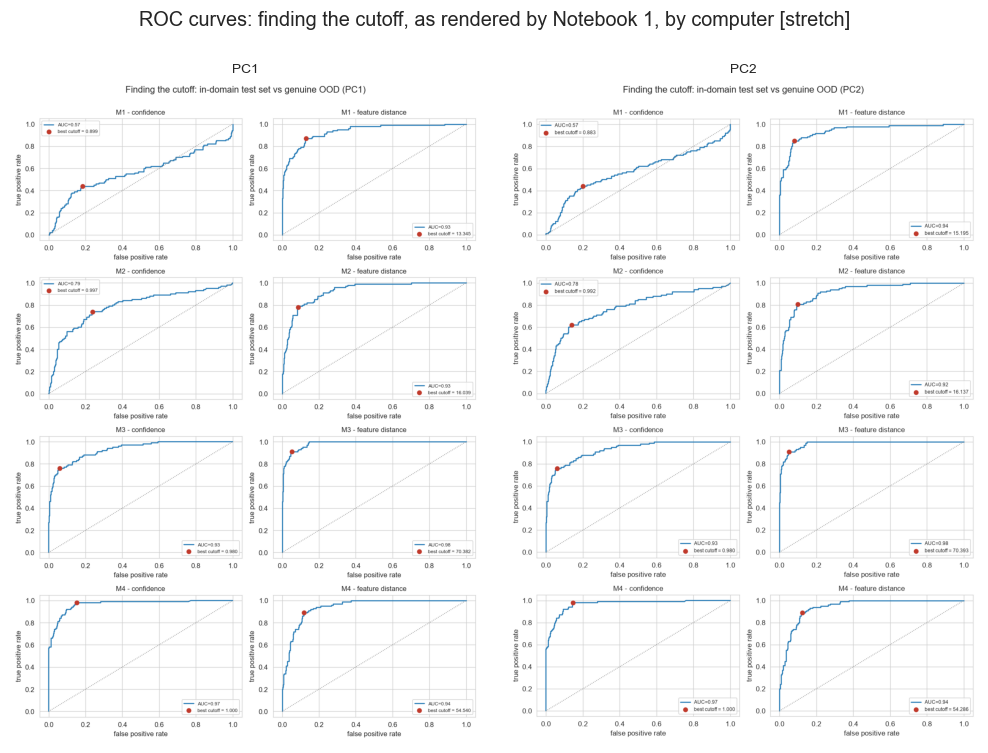

  (missing: ['PC3', 'PC4'])


In [ ]:
if HAVE["cutoff"]:
    computers_with_cutoff = sorted(pc for pc, d in PC_DIRS.items() if os.path.exists(f"{d}/ood/cutoff_analysis_{pc}.csv"))
    print(f"Cutoff-analysis data found for {len(computers_with_cutoff)}/{len(PC_DIRS)} computers: {computers_with_cutoff}")
    if len(computers_with_cutoff) < len(PC_DIRS):
        missing_cutoff = sorted(set(PC_DIRS) - set(computers_with_cutoff))
        print(f"  Missing from: {missing_cutoff} - this means that computer's Notebook 1 Section 18.y never ran, which")
        print("  happens when RUN_STRETCH was off there, OR OOD_Examples/Metadata/ood_metadata.csv wasn't present/found")
        print(f"  on that computer at the time. Check those {len(missing_cutoff)} computer(s)' own results/ood/ folder for")
        print("  cutoff_analysis_*.csv and ood_examples_results_*.csv to confirm which it was - this notebook is only")
        print("  showing what each computer's own submitted ZIP actually contains, not filtering anything out itself.")

    cutoff_dfs = []
    for pc, d in PC_DIRS.items():
        df = read_csv(f"{d}/ood/cutoff_analysis_{pc}.csv")
        if df is not None:
            df = df.copy(); df["computer"] = pc
            cutoff_dfs.append(df)
    if cutoff_dfs:
        combined_reliability_df = pd.concat(cutoff_dfs, ignore_index=True)
        combined_reliability_df = combined_reliability_df[
            [f"{r.model}_{r.computer}" in VALID_RUNS for r in combined_reliability_df.itertuples()]]
        print(combined_reliability_df.to_string(index=False))
        combined_reliability_df.to_csv(f"{DIRS['tables']}/combined_reliability_cutoffs.csv", index=False)

        numeric = combined_reliability_df.copy()
        numeric["recommended_cutoff"] = pd.to_numeric(numeric["recommended_cutoff"], errors="coerce")
        numeric["configured_cutoff"] = pd.to_numeric(numeric["configured_cutoff"], errors="coerce")
        numeric = numeric.dropna(subset=["recommended_cutoff", "configured_cutoff"])
        numeric = numeric[np.isfinite(numeric["recommended_cutoff"]) & np.isfinite(numeric["configured_cutoff"])]
        if len(numeric):
            fig, ax = plt.subplots(figsize=(6, 5.5))
            for signal, g in numeric.groupby("signal"):
                ax.scatter(g["configured_cutoff"], g["recommended_cutoff"], label=signal, s=60)
            lo = min(numeric["configured_cutoff"].min(), numeric["recommended_cutoff"].min())
            hi = max(numeric["configured_cutoff"].max(), numeric["recommended_cutoff"].max())
            ax.plot([lo, hi], [lo, hi], linestyle=":", color="grey", label="configured = recommended")
            ax.set_xlabel("configured cutoff"); ax.set_ylabel("data-driven recommended cutoff")
            ax.legend(fontsize=8)
            fig.suptitle("Configured vs data-driven cutoff, by signal", fontsize=12)
            fig.tight_layout()
            save_fig(fig, "cutoff_scatter")
    else:
        combined_reliability_df = pd.DataFrame()
        print("No cutoff-analysis files found among valid runs.")
else:
    combined_reliability_df = pd.DataFrame()
    print("No combined-reliability/cutoff outputs found in any result file - Section 15 skipped.")

roc_paths = [(f"{d}/ood/cutoff_analysis_{pc}.png", pc) for pc, d in PC_DIRS.items()]
show_images_grid(roc_paths, "ROC curves: finding the cutoff, as rendered by Notebook 1, by computer [stretch]", ncols=2)

#### Reasoning: Exploratory, Not a Guarantee
Sections 12–15 describe how each signal behaved on the specific test, TTA sample and OOD images each computer used - useful for comparing the four models to each other, but **not evidence that unsupported-input rejection works in general**. Notebook 1's own Critical Limitation note (Section 18) already stated this: without a genuinely independent OOD evaluation set, no notebook in this project can claim reliable OOD detection. These sections are labelled STRETCH for that reason, and Section 18's final selection treats them as one input among several, not a pass/fail gate on their own.

## 16. Computational Comparison
Parameter counts, checkpoint size, training time and CPU inference time, averaged across valid runs. **Training/inference times are hardware-dependent** (Section 8's environment table) - the ordering *between models on the same computer* is informative; absolute milliseconds compared *across* computers are not.

       Params (total)  Checkpoint (MB)  Train time (s)  Inference (ms/image, CPU)
model                                                                            
M1           389890.0             1.50          925.77                       8.43
M2          1174690.0             4.50         4395.88                      18.51
M3          4010110.0            15.57          369.65                      24.22
M4          4010110.0            15.57          453.59                      22.29


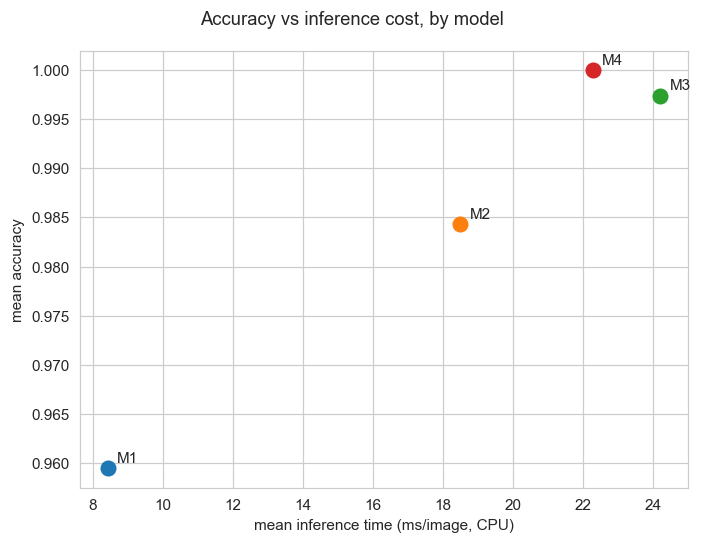

In [ ]:
if HAVE["computational"]:
    comp_dfs = []
    for pc, d in PC_DIRS.items():
        df = read_csv(f"{d}/computational/computational_comparison_{pc}.csv")
        if df is not None:
            df = df.copy(); df["computer"] = pc
            comp_dfs.append(df)
    if comp_dfs:
        computational_df = pd.concat(comp_dfs, ignore_index=True).rename(columns={"Model": "model"})
        computational_df = computational_df[[f"{r.model}_{r.computer}" in VALID_RUNS for r in computational_df.itertuples()]]
        summary_cols = [c for c in ["Params (total)", "Checkpoint (MB)", "Train time (s)", "Inference (ms/image, CPU)"]
                        if c in computational_df.columns]
        print(computational_df.groupby("model")[summary_cols].mean().round(2).to_string())
        computational_df.to_csv(f"{DIRS['tables']}/computational_comparison.csv", index=False)

        if "Inference (ms/image, CPU)" in computational_df.columns and len(all_results_df):
            acc_by_model = all_results_df.groupby("model")["accuracy"].mean()
            inf_by_model = computational_df.groupby("model")["Inference (ms/image, CPU)"].mean()
            fig, ax = plt.subplots(figsize=(6.5, 5))
            for m in MODEL_IDS:
                if m in acc_by_model.index and m in inf_by_model.index:
                    ax.scatter(inf_by_model[m], acc_by_model[m], s=90)
                    ax.annotate(m, (inf_by_model[m], acc_by_model[m]), textcoords="offset points", xytext=(6, 4))
            ax.set_xlabel("mean inference time (ms/image, CPU)"); ax.set_ylabel("mean accuracy")
            fig.suptitle("Accuracy vs inference cost, by model", fontsize=12)
            fig.tight_layout()
            save_fig(fig, "accuracy_vs_cost")
    else:
        computational_df = pd.DataFrame()
        print("No computational-comparison files found among valid runs.")
else:
    computational_df = pd.DataFrame()
    print("No computational outputs found in any result file - Section 16 skipped.")

## 17. Statistical & Practical Comparison
**The four computers are repeated measurements of the same training runs on the same test set, not four independent datasets** - they speak to the reproducibility of these specific models, not to generalisation beyond this data. With at most 4 paired computers, a formal significance test (e.g. a paired t-test) would have very low power, so this reports the paired per-computer difference and whether its direction is consistent across every computer instead of a p-value.

M2_vs_M1: per-computer diffs = {'PC1': 0.0262, 'PC2': 0.0236, 'PC3': 0.0262, 'PC4': 0.0236}
   mean +0.0249  std 0.0015  same direction on every computer: True

M3_vs_M2: per-computer diffs = {'PC1': 0.0105, 'PC2': 0.0131, 'PC3': 0.0131, 'PC4': 0.0157}
   mean +0.0131  std 0.0021  same direction on every computer: True

M4_vs_M3: per-computer diffs = {'PC1': 0.0026, 'PC2': 0.0026, 'PC3': 0.0026, 'PC4': 0.0026}
   mean +0.0026  std 0.0000  same direction on every computer: True



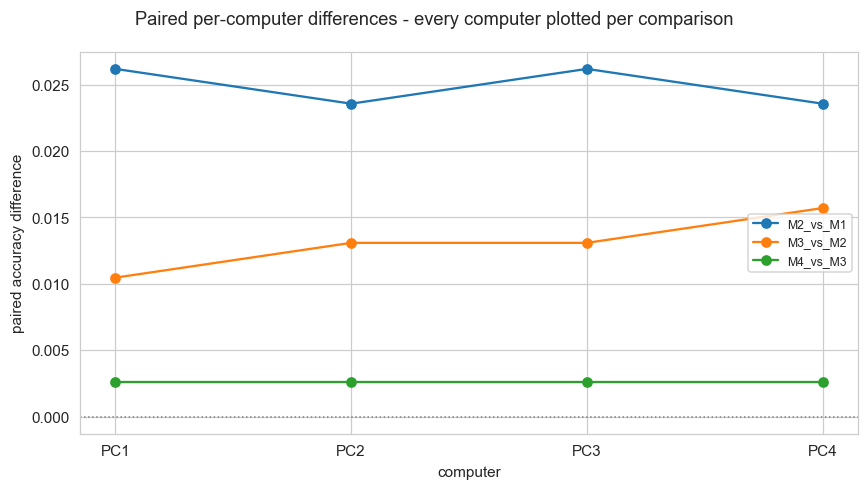

In [ ]:
def paired_diff(model_a, model_b, metric="accuracy"):
    if not len(all_results_df):
        return None
    sub = all_results_df[all_results_df["model"].isin([model_a, model_b])]
    pivot = sub.pivot(index="computer", columns="model", values=metric)
    if model_a not in pivot.columns or model_b not in pivot.columns:
        return None
    return (pivot[model_a] - pivot[model_b]).dropna()

comparisons = [("M2_vs_M1", "M2", "M1"), (f"M3_vs_{best_custom}", "M3", best_custom), ("M4_vs_M3", "M4", "M3")]
statistical_rows = []
for label, a, b in comparisons:
    diffs = paired_diff(a, b)
    if diffs is None or len(diffs) == 0:
        print(f"{label}: not enough paired computers to compare")
        continue
    consistent = bool((diffs > 0).all() or (diffs < 0).all())
    print(f"{label}: per-computer diffs = {diffs.round(4).to_dict()}")
    print(f"   mean {diffs.mean():+.4f}  std {diffs.std():.4f}  same direction on every computer: {consistent}\n")
    statistical_rows.append({"comparison": label, "n_computers": len(diffs), "mean_diff": diffs.mean(),
                             "std_diff": diffs.std(), "consistent_direction": consistent})

statistical_comparison_df = pd.DataFrame(statistical_rows)
statistical_comparison_df.to_csv(f"{DIRS['tables']}/statistical_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, a, b in comparisons:
    diffs = paired_diff(a, b)
    if diffs is None or len(diffs) == 0:
        continue
    ordered = diffs.reindex([pc for pc in COMPUTER_IDS if pc in diffs.index])
    ax.plot(ordered.index, ordered.values, marker="o", label=label)
ax.axhline(0, color="grey", linestyle=":", linewidth=1)
ax.set_ylabel("paired accuracy difference"); ax.set_xlabel("computer")
ax.legend(fontsize=8)
fig.suptitle("Paired per-computer differences - every computer plotted per comparison", fontsize=12)
fig.tight_layout()
save_fig(fig, "paired_differences_by_computer")

## 18. Final Model Selection
Predictive performance, reliability, source balance and computational cost side by side, then one explicit, inspectable decision rule applied to them - **not an automatic pick of the highest accuracy, and not an automatic pick of M4.** The test set has already been used once, for this evaluation; nothing below re-touches it to search for a better threshold or configuration.

In [ ]:
selection_table = pd.DataFrame(index=pd.Index(MODEL_IDS, name="model"))
if len(all_results_df):
    g = all_results_df.groupby("model")
    selection_table["mean_accuracy"] = g["accuracy"].mean()
    selection_table["mean_f1"] = g["f1"].mean()
    selection_table["accuracy_spread"] = g["accuracy"].agg(lambda s: s.max() - s.min())
if len(confidence_analysis_df):
    cg = confidence_analysis_df.groupby("model")
    selection_table["incorrect_high_rate"] = cg["incorrect_high"].mean()
    selection_table["roc_auc"] = cg["roc_auc"].mean()
if len(source_generalisation_df):
    sg = source_generalisation_df.groupby(["model", "source"])["Accuracy"].mean().unstack()
    if "Student" in sg.columns and "Public" in sg.columns:
        selection_table["source_gap"] = (sg["Student"] - sg["Public"]).abs()
if len(computational_df):
    cdg = computational_df.groupby("model")
    if "Params (total)" in computational_df.columns:
        selection_table["mean_params"] = cdg["Params (total)"].mean()
    if "Inference (ms/image, CPU)" in computational_df.columns:
        selection_table["mean_inference_ms"] = cdg["Inference (ms/image, CPU)"].mean()
if len(ood_results_df):
    selection_table["ood_wrongly_accepted_rate"] = ood_results_df.groupby("model")["rate"].mean()

print(selection_table.round(4).to_string())
selection_table.to_csv(f"{DIRS['tables']}/selection_criteria.csv")

       mean_accuracy  mean_f1  accuracy_spread  incorrect_high_rate  roc_auc  source_gap  mean_params  mean_inference_ms  ood_wrongly_accepted_rate
model                                                                                                                                              
M1            0.9594   0.9594           0.0026                 1.75   0.9925      0.0079     389890.0             8.4329                      0.075
M2            0.9843   0.9843           0.0052                 0.00   0.9996      0.0314    1174690.0            18.5071                      0.130
M3            0.9974   0.9974           0.0000                 0.00   1.0000      0.0052    4010110.0            24.2161                      0.000
M4            1.0000   1.0000           0.0000                 0.00   1.0000      0.0000    4010110.0            22.2869                      0.000


#### Reasoning: Several Explicit Conditions, Not the Only Valid Set
Five conditions, in order, each auditable from the table above: a clear confidence-reliability problem (Step 1), a clear source-fairness problem (Step 2), a clear OOD-rejection problem (Step 3), a cross-computer spread flag that informs but doesn't eliminate on its own (Step 4), and finally accuracy with a reproducibility-aware tiebreak (Step 5). A different team could reasonably weight these differently (e.g. prioritising raw accuracy, ruling out custom CNNs for maintainability, or treating Step 4's spread as a hard cutoff rather than a flag) - Section 18's table exists so that alternative can be built on the same evidence, not so this one rule is the final word.

Elimination log:
  M1: confidently-wrong rate 1.750 is a clear outlier vs the other models ({'M2': np.float64(0.0), 'M3': np.float64(0.0), 'M4': np.float64(0.0)})
  M2: OOD wrongly-accepted rate 0.130 is a clear outlier vs the other models ({'M1': np.float64(0.075), 'M3': np.float64(0.0), 'M4': np.float64(0.0)})

Selected model: M4
Rationale: Highest mean accuracy (1.0000); within 0.005 of M3 but consistently outperformed it on every paired computer (Section 17), so the small margin is treated as real, not noise.


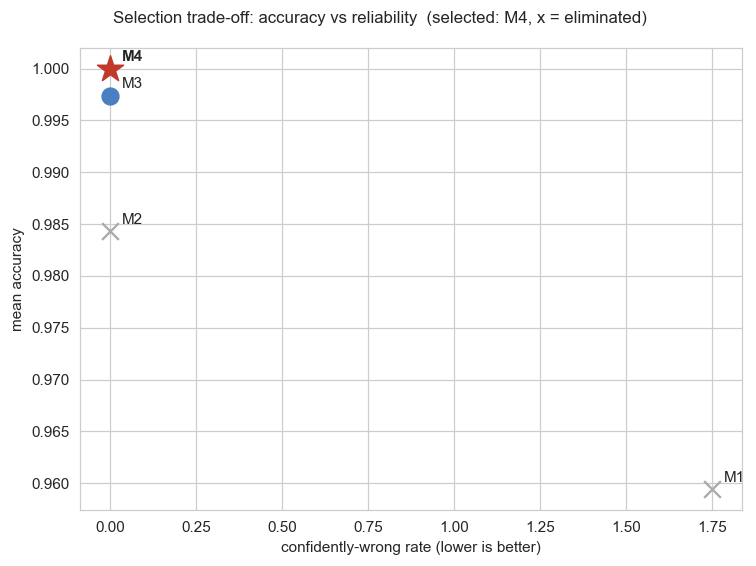

In [ ]:
TIE_BAND = 0.005          # accuracy differences smaller than this are not AUTOMATICALLY meaningful -
                         # but see Step 3: a difference this small is still honoured if it is consistent
                         # (same sign on every paired computer), since that is reproducibility, not noise.
RELIABILITY_OUTLIER_FACTOR = 2.0    # a model is "clearly worse" on a signal if it's >2x the field's baseline
SOURCE_GAP_LIMIT = 0.05

candidates = list(selection_table.index)
elimination_log = []

def eliminate(model, reason):
    if model in candidates:
        candidates.remove(model)
        elimination_log.append({"model": model, "step": reason})

def consistently_better(a, b, metric="accuracy"):
    """True/False if `a` beats/loses to `b` on EVERY paired computer (reuses Section 17's paired_diff);
    None if the sign is mixed across computers, or too few computers are paired to tell."""
    diffs = paired_diff(a, b, metric)
    if diffs is None or len(diffs) == 0:
        return None
    if (diffs > 0).all():
        return True
    if (diffs < 0).all():
        return False
    return None

# Step 1: a model with a confidently-wrong rate far above the rest of the field is eliminated first.
# Comparing against the OTHER models (not including itself) and falling back to their max when their
# median is 0 means a single bad model is still caught even when most models have zero such mistakes -
# a median-only comparison would silently never flag anyone in that (common) all-but-one-perfect case.
if "incorrect_high_rate" in selection_table.columns and selection_table["incorrect_high_rate"].notna().any():
    for m in list(candidates):
        v = selection_table.loc[m, "incorrect_high_rate"]
        others = selection_table["incorrect_high_rate"].drop(index=m, errors="ignore").dropna()
        if pd.isna(v) or len(others) == 0:
            continue
        baseline = others.median()
        is_outlier = v > 0 and (v > baseline * RELIABILITY_OUTLIER_FACTOR if baseline > 0 else v > others.max())
        if is_outlier:
            eliminate(m, f"confidently-wrong rate {v:.3f} is a clear outlier vs the other models ({dict(others.round(3))})")

# Step 2: a model with a source-balance gap over the limit is eliminated next, UNLESS that would eliminate everyone
if "source_gap" in selection_table.columns and selection_table["source_gap"].notna().any():
    over_limit = [m for m in candidates if pd.notna(selection_table.loc[m, "source_gap"])
                 and selection_table.loc[m, "source_gap"] > SOURCE_GAP_LIMIT]
    if over_limit and len(over_limit) < len(candidates):
        for m in over_limit:
            eliminate(m, f"student/public accuracy gap {selection_table.loc[m, 'source_gap']:.3f} exceeds {SOURCE_GAP_LIMIT}")

# Step 3: a model whose rate of wrongly-accepting genuine OOD images is a clear outlier is eliminated
# next, using the same others-not-self, median-or-max baseline as Step 1 - a model that is accurate on
# Apple/Banana but systematically fails to say "Unable to confidently classify this image" is not a safe
# default for a deployed app, independent of its raw accuracy.
OOD_OUTLIER_FACTOR = 2.0
if "ood_wrongly_accepted_rate" in selection_table.columns and selection_table["ood_wrongly_accepted_rate"].notna().any():
    for m in list(candidates):
        v = selection_table.loc[m, "ood_wrongly_accepted_rate"]
        others = selection_table["ood_wrongly_accepted_rate"].drop(index=m, errors="ignore").dropna()
        if pd.isna(v) or len(others) == 0:
            continue
        baseline = others.median()
        is_outlier = v > 0 and (v > baseline * OOD_OUTLIER_FACTOR if baseline > 0 else v > others.max())
        if is_outlier:
            eliminate(m, f"OOD wrongly-accepted rate {v:.3f} is a clear outlier vs the other models ({dict(others.round(3))})")

# Step 4: a model is not eliminated for a wide cross-computer accuracy spread alone (4 computers is too
# few to be confident that's a real effect and not noise - Section 8), but it IS flagged here so the
# team can weigh it, since it speaks to how reproducible this model's deployment behaviour will be.
reproducibility_flags = []
if "accuracy_spread" in selection_table.columns and selection_table["accuracy_spread"].notna().any():
    wide_spread = selection_table[selection_table["accuracy_spread"] > 0.03]
    for m in wide_spread.index:
        if m in candidates:
            reproducibility_flags.append({"model": m, "accuracy_spread": float(wide_spread.loc[m, "accuracy_spread"])})

# Step 5: among what's left, rank by accuracy - but a model within TIE_BAND of the leader is NOT treated
# as a tie if the leader consistently beats it on every paired computer (Section 17): a perfectly
# reproducible difference is evidence, however small, not noise. Only a genuinely ambiguous case (mixed
# sign, or too few paired computers to tell) falls back to the parameter-count tiebreak.
if not candidates:
    SELECTED_MODEL = None
    SELECTION_RATIONALE = "Every model was eliminated by the reliability/fairness steps above - no model meets the bar as evaluated."
elif "mean_accuracy" not in selection_table.columns:
    SELECTED_MODEL = candidates[0]
    SELECTION_RATIONALE = "No accuracy data was available to rank the remaining candidates; first remaining candidate kept."
else:
    acc = selection_table.loc[candidates, "mean_accuracy"].sort_values(ascending=False)
    best = acc.index[0]
    confirmed_wins = []
    tie_resolved = False
    for other in acc.index[1:]:
        if acc[best] - acc[other] > TIE_BAND:
            break                                     # remaining candidates are too far behind to matter
        if consistently_better(best, other):
            confirmed_wins.append(other)               # best wins every computer despite the small gap - keep it
            continue
        tied = [m for m in acc.index if acc[best] - acc[m] <= TIE_BAND and m not in confirmed_wins]
        cost = selection_table.loc[tied, "mean_params"] if "mean_params" in selection_table.columns else pd.Series(index=tied, dtype=float)
        if cost.notna().any() and cost.nunique() > 1:
            best = cost.idxmin()
            SELECTION_RATIONALE = (f"Tied on accuracy (within {TIE_BAND}) with {tied}, with no consistent winner across "
                                   f"computers between them; chose {best}, the lowest parameter count among the tied models "
                                   f"({cost.min():,.0f} params).")
        else:
            SELECTION_RATIONALE = (f"Tied on accuracy (within {TIE_BAND}) with {tied}, with no consistent winner across "
                                   f"computers and no cost difference to break the tie; kept {best} (highest mean accuracy).")
        tie_resolved = True
        break
    if not tie_resolved:
        if confirmed_wins:
            who = confirmed_wins[0] if len(confirmed_wins) == 1 else confirmed_wins
            SELECTION_RATIONALE = (f"Highest mean accuracy ({acc[best]:.4f}); within {TIE_BAND} of {who} but consistently "
                                   f"outperformed {'it' if len(confirmed_wins) == 1 else 'all of them'} on every paired "
                                   f"computer (Section 17), so the small margin is treated as real, not noise.")
        else:
            SELECTION_RATIONALE = f"Highest mean accuracy among models that passed the reliability/fairness checks ({acc[best]:.4f})."
    SELECTED_MODEL = best

print("Elimination log:")
for e in elimination_log:
    print(f"  {e['model']}: {e['step']}")
if reproducibility_flags:
    print("\nFlagged, not eliminated (wide cross-computer accuracy spread - see Section 8):")
    for f_ in reproducibility_flags:
        print(f"  {f_['model']}: spread {f_['accuracy_spread']:.4f}")
print(f"\nSelected model: {SELECTED_MODEL}")
print(f"Rationale: {SELECTION_RATIONALE}")

with open(f"{DIRS['selection']}/elimination_log.json", "w") as f:
    json.dump({"eliminated": elimination_log, "flagged_not_eliminated": reproducibility_flags}, f, indent=2, default=str)

if "mean_accuracy" in selection_table.columns:
    fig, ax = plt.subplots(figsize=(7, 5.2))
    x_col = "incorrect_high_rate" if "incorrect_high_rate" in selection_table.columns else None
    for m in selection_table.index:
        xv = selection_table.loc[m, x_col] if x_col is not None and pd.notna(selection_table.loc[m, x_col]) else 0
        yv = selection_table.loc[m, "mean_accuracy"]
        if pd.isna(yv):
            continue
        is_selected = (m == SELECTED_MODEL)
        eliminated = m not in candidates and not is_selected
        color = "#c0392b" if is_selected else ("#aaaaaa" if eliminated else "#4a7fc1")
        marker = "*" if is_selected else ("x" if eliminated else "o")
        size = 320 if is_selected else 120
        ax.scatter(xv, yv, s=size, color=color, marker=marker, zorder=5 if is_selected else 3)
        ax.annotate(m, (xv, yv), textcoords="offset points", xytext=(8, 5), fontsize=10,
                   fontweight="bold" if is_selected else "normal")
    ax.set_xlabel("confidently-wrong rate (lower is better)"); ax.set_ylabel("mean accuracy")
    fig.suptitle(f"Selection trade-off: accuracy vs reliability  (selected: {SELECTED_MODEL}, x = eliminated)", fontsize=11)
    fig.tight_layout()
    save_fig(fig, "selection_tradeoff")

## 19. Deployment Record
**The application loads the selected model automatically; the user never chooses one.** This records exactly which checkpoint, configuration and dataset version that selection refers to, so a deployed build can be traced back to one specific, reproducible training run rather than "whichever M3 happened to be lying around".

In [ ]:
chosen_log, chosen_eid = None, None
if SELECTED_MODEL and len(all_results_df):
    candidates_df = all_results_df[all_results_df["model"] == SELECTED_MODEL].sort_values("accuracy", ascending=False)
    if len(candidates_df):
        chosen_eid = candidates_df.iloc[0]["run_id"]
        chosen_log = EXPERIMENT_LOGS.get(chosen_eid)

deployment_record = {
    "selected_model": SELECTED_MODEL, "selection_rationale": SELECTION_RATIONALE, "elimination_log": elimination_log,
    "recommended_checkpoint_run": chosen_eid,
    "checkpoint_path": chosen_log.get("checkpoint_path") if chosen_log else None,
    "config_hash": chosen_log.get("config_hash") if chosen_log else None,
    "dataset_version": chosen_log.get("dataset_version") if chosen_log else None,
    "dataset_fingerprint": chosen_log.get("dataset_fingerprint") if chosen_log else None,
    "preprocessing_version": chosen_log.get("preprocessing_version") if chosen_log else None,
    "hyperparameters": chosen_log.get("hyperparameters") if chosen_log else None,
    "notebook_version": chosen_log.get("notebook_version") if chosen_log else None,
    "recorded_at": datetime.datetime.now().isoformat(timespec="seconds"),
}
print(json.dumps({k: v for k, v in deployment_record.items() if k != "hyperparameters"}, indent=2, default=str))
if chosen_log is None:
    print("\nWARNING!!! No checkpoint could be matched to the selected model - check Section 3's validity report.")

with open(f"{DIRS['selection']}/final_model_selection.json", "w") as f:
    json.dump(deployment_record, f, indent=2, default=str)

{
  "selected_model": "M4",
  "selection_rationale": "Highest mean accuracy (1.0000); within 0.005 of M3 but consistently outperformed it on every paired computer (Section 17), so the small margin is treated as real, not noise.",
  "elimination_log": [
    {
      "model": "M1",
      "step": "confidently-wrong rate 1.750 is a clear outlier vs the other models ({'M2': np.float64(0.0), 'M3': np.float64(0.0), 'M4': np.float64(0.0)})"
    },
    {
      "model": "M2",
      "step": "OOD wrongly-accepted rate 0.130 is a clear outlier vs the other models ({'M1': np.float64(0.075), 'M3': np.float64(0.0), 'M4': np.float64(0.0)})"
    }
  ],
  "recommended_checkpoint_run": "M4_PC1",
  "checkpoint_path": "results/checkpoints/M4_PC1.pt",
  "config_hash": "d7e2e21cf167",
  "dataset_version": "Apple_Banana_Dataset_(Final)",
  "dataset_fingerprint": "52b395cdef84b0ff",
  "preprocessing_version": "PP_v1: EXIF-upright, RGB, bicubic resize 128x128, pixels 0-1",
  "notebook_version": "v1.0",
  "recorde

## 19. Final Exports
Everything produced above already lives under `collation_results/tables/`, `/figures/`, `/audit/` and `/selection/`. This section writes one top-level manifest and a human-readable summary, then zips the folder.

```
collation_results/
├── tables/      (all_experiment_results, model_comparison_summary, reproducibility_summary,
│                 source_generalisation_results, error_analysis, confidence_analysis, ood_results, ...)
├── figures/     (confusion matrices, learning curves, accuracy chart, PCA grids, ...)
├── audit/       (run_registry.csv, test_set_consistency.json)
└── selection/   (elimination_log.json, final_model_selection.json)
```

In [ ]:
manifest_out = {
    "generated_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "computers_submitted": sorted(PC_DIRS.keys()), "runs_present": n_present, "runs_valid": n_valid,
    "invalid_runs": invalid[["run_id", "reasons"]].to_dict("records") if len(invalid) else [],
    "test_set_consistent": TEST_SET_CONSISTENT,
    "selected_model": SELECTED_MODEL, "selection_rationale": SELECTION_RATIONALE,
    "files": sorted(os.path.relpath(p, OUTPUT_DIR) for p in glob.glob(f"{OUTPUT_DIR}/**/*", recursive=True)
                    if os.path.isfile(p) and "_extracted" not in p),
}
with open(f"{OUTPUT_DIR}/manifest.json", "w") as f:
    json.dump(manifest_out, f, indent=2, default=str)

print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
print(f"Computers submitted : {sorted(PC_DIRS.keys())}")
print(f"Runs present/valid  : {n_present}/{len(EXPECTED_RUNS)} present, {n_valid}/{len(EXPECTED_RUNS)} valid")
if len(invalid):
    print(f"Excluded runs       : {list(invalid['run_id'])}")
print(f"Test-set consistency: {'OK' if TEST_SET_CONSISTENT else 'NOT CONSISTENT - see Section 4'}")
if len(all_results_df):
    print(f"\nMean test accuracy by model (valid runs):")
    print(all_results_df.groupby('model')['accuracy'].mean().reindex(MODEL_IDS).round(4).to_string())
print(f"\nSelected model: {SELECTED_MODEL}")
print(f"Rationale     : {SELECTION_RATIONALE}")

zip_path = shutil.make_archive("Collation_results", "zip", OUTPUT_DIR, base_dir=".")
print(f"\nAll outputs saved under {OUTPUT_DIR}/ and zipped to {zip_path}")
print("\nThis notebook ends at an evidence-based, recorded selection - not at retraining or redeploying anything.")

FINAL SUMMARY
Computers submitted : ['PC1', 'PC2', 'PC3', 'PC4']
Runs present/valid  : 16/16 present, 16/16 valid
Test-set consistency: OK

Mean test accuracy by model (valid runs):
model
M1    0.9594
M2    0.9843
M3    0.9974
M4    1.0000

Selected model: M4
Rationale     : Highest mean accuracy (1.0000); within 0.005 of M3 but consistently outperformed it on every paired computer (Section 17), so the small margin is treated as real, not noise.

All outputs saved under ./Collation_results/ and zipped to c:\Users\User1\Documents\Computer Science\COMP6900\Collation_results.zip

This notebook ends at an evidence-based, recorded selection - not at retraining or redeploying anything.
